> **About this notebook.** I wrote this check notebook to prove that every number on our final presentation slides and Power BI dashboard can be re-derived from the raw data: each number is computed three different ways (for example a pandas filter, a group-by and a plain loop) and compared with the slide.
> Result of the saved run: 164 numbers PASS, 7 BUILD (model numbers a few cases off because of a different xgboost build), 0 CHECK. Sections G and H refer to the team's final model, built by a teammate (the modelling lead); this notebook re-runs its published settings only to check the deck's numbers. Outputs show stock codes and ranks only, never a firm's financial figures. Data not included (academic-use licence).


# Check the deck's numbers yourself

This notebook starts from the raw file **Copy of ST_data.xlsx** and works forward, step by step, to the numbers on the final slides. It covers loading, cleaning, the OLAP numbers (done here in pandas, **no SQL**), the EDA, the team model's data steps, and the model. Run it top to bottom, then read the line printed under each step.

**Three ways for every number.** Each number is worked out three different ways, for example with a pandas filter, with a group-by table and with a plain Python loop. If all three ways agree with each other and with the slide, the line says `PASS`.

| Result | Meaning |
|---|---|
| `PASS` | All three ways give the number printed on the slide. |
| `BUILD` | The number comes from the XGBoost model. The three ways agree with each other, and the result is within a few cases of the slide, but not exactly the same. That is expected: the modelling lead's laptop used a different xgboost build, so tiny differences in the trees move a few firms. The slide keeps the original number. |
| `CHECK` | The three ways disagree, or the result is far from the slide. Stop and look at that line. |

**What it needs.** The two Excel files (`Copy of ST_data.xlsx` and `cleaned_data.xlsx`) and the packages in `requirements.txt`: pandas, numpy, scipy, scikit-learn, matplotlib, openpyxl, xgboost, optuna, shap. It runs in about 3 minutes, most of it spent reading the Excel files. It writes only one small file, `verify_deck_checks.csv`, next to this notebook.

**Data rule.** ZxData is for academic use only. This notebook prints counts, rates and ranks, never one named firm's financial figures. Do not upload its output anywhere.

## 0. Settings: where the files are

In [1]:
import os, time, warnings
from pathlib import Path

# If the notebook cannot find a file, type its full path between the quotes, e.g. r"C:\ST_Project\Copy of ST_data.xlsx"
RAW_PATH = r""          # Copy of ST_data.xlsx
CLEANED_PATH = r""      # cleaned_data.xlsx (the team's cleaned file, used to compare against our rebuild)
SCORES_PATH = r""       # optional: the Power BI scores file team_risk_scores_2019_2024.csv

def find(name, typed, env):
    """Use the typed path, then an environment variable, then look in this folder, the folders above it and the usual sub-folders."""
    for p in [typed, os.environ.get(env, "")]:
        if p and Path(p).exists():
            return Path(p)
    here = Path.cwd().resolve()
    for base in [here, *list(here.parents)[:4]]:
        for sub in ["", "data", "outputs/end_to_end", "v2_star/outputs/end_to_end", "pal-breakdown/v2_star/outputs/end_to_end",
                    "powerbi/data", "v2_star/powerbi/data", "pal-breakdown/v2_star/powerbi/data", "st_data_pull", "st_data_pull/powerbi/data",
                    "st_data_pull/st_data_pull", "st_data_pull/st_data_pull/powerbi/data", "Downloads/st_data_pull/st_data_pull/powerbi/data"]:
            p = base / sub / name
            if p.exists():
                return p
    for p in [Path(r"C:\ST_Project") / name, Path(r"C:\ST_Project\pal-breakdown\v2_star\outputs\end_to_end") / name,
              Path.home() / "Downloads" / "st_data_pull" / "st_data_pull" / "powerbi" / "data" / name]:
        if p.exists():
            return p
    return None

RAW = find("Copy of ST_data.xlsx", RAW_PATH, "ST_DATA_PATH")
CLEANED = find("cleaned_data.xlsx", CLEANED_PATH, "ST_CLEANED_PATH")
SCORES = find("team_risk_scores_2019_2024.csv", SCORES_PATH, "ST_SCORES_PATH")
print("Raw file     :", RAW)
print("Cleaned file :", CLEANED)
print("Scores file  :", SCORES, "(optional)")
assert RAW is not None and CLEANED is not None, "Type the two Excel paths into RAW_PATH and CLEANED_PATH above, then run this cell again."

Raw file     : <project>/Copy of ST_data.xlsx
Cleaned file : <project>/pal-breakdown/v2_star/outputs/end_to_end/cleaned_data.xlsx
Scores file  : <project>/pal-breakdown/v2_star/powerbi/data/team_risk_scores_2019_2024.csv (optional)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
NAVY, GREY = "#2D3986", "#B2B4BC"

RESULTS = []

def check(slide, label, deck, ways, decimals=0, build=False, near=None):
    """Compare three ways of getting a number with the number on the slide.

    deck     : the number printed on the slide
    ways     : {"name of the way": value} - normally three entries
    decimals : how many decimals the slide shows (values are rounded to that before comparing)
    build    : True for numbers that come from the XGBoost model (see the BUILD row in the table at the top)
    near     : for build numbers, how far from the slide still counts as BUILD rather than CHECK
    """
    vals = {k: round(float(v), decimals) for k, v in ways.items()}
    agree = len(set(vals.values())) == 1
    same_as_deck = agree and abs(next(iter(vals.values())) - deck) < 0.5 * 10 ** -decimals + 1e-9
    if same_as_deck:
        result = "PASS"
    elif build and agree and near is not None and abs(next(iter(vals.values())) - deck) <= near:
        result = "BUILD"
    else:
        result = "CHECK"
    is_year = decimals == 0 and "year" in label.lower() and all(1900 <= v <= 2100 for v in [deck, *vals.values()])
    fmt = "{:.0f}" if is_year else f"{{:,.{decimals}f}}"
    shown = " | ".join(f"{k}: {fmt.format(v)}" for k, v in vals.items())
    where = "dashboard" if slide == "dash" else f"slide {slide}"
    said = "expected" if slide == "dash" else "slide says"
    print(f"{result:<5} | {where} | {label}: {said} {fmt.format(deck)} | {shown}")
    RESULTS.append({"result": result, "slide": slide, "check": label, "slide value": deck,
                    **{f"way {i}": f"{k} = {fmt.format(v)}" for i, (k, v) in enumerate(vals.items(), 1)}})
print("Ready.")

Ready.


## A. Load the raw data (slides 4 and 10)

The raw file has one row per listed firm per year (a "firm-year"). `ST = 1` means the firm carried an ST, \*ST or PT label at the end of that year.

In [3]:
t0 = time.time()
raw = pd.read_excel(RAW, sheet_name="ST_data").sort_values(["stkcd", "year"]).reset_index(drop=True)
for col in ["ST", "ST_next1", "ST_next2", "region_code", "Big4"]:
    raw[col] = pd.to_numeric(raw[col])
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns in {time.time() - t0:.0f} s; years {raw.year.min()}-{raw.year.max()}")
raw.groupby("year").size().rename("firm-years").to_frame().T

Loaded 62,669 rows x 48 columns in 19 s; years 2001-2024


year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
firm-years,1010,1072,1138,1234,1240,1279,1364,1476,1582,1903,...,2553,2826,3251,3479,3683,4113,4635,5061,5311,5258


In [4]:
rows_by_year = raw.groupby("year").size()
check(4, "firm-years, 2001-2024", 62669, {"len(table)": len(raw), "sum of rows per year": rows_by_year.sum(),
                                          "count with a loop": sum(1 for _ in raw.itertuples())})
check(4, "listed firms", 5365, {"nunique()": raw.stkcd.nunique(), "group-by count": len(raw.groupby("stkcd")),
                                "Python set": len(set(raw.stkcd))})
check(4, "ST firm-years", 2129, {"sum of ST": raw.ST.sum(), "value_counts": raw.ST.value_counts()[1.0],
                                 "loop": sum(1 for v in raw.ST if v == 1)})
check(4, "share of firm-years that were ST (%)", 3.40, {"2,129 / 62,669": 100 * raw.ST.sum() / len(raw),
                                                         "mean of ST": 100 * raw.ST.fillna(0).mean(),
                                                         "weighted by year": 100 * (raw.groupby("year").ST.sum().sum() / rows_by_year.sum())}, 2)

PASS  | slide 4 | firm-years, 2001-2024: slide says 62,669 | len(table): 62,669 | sum of rows per year: 62,669 | count with a loop: 62,669
PASS  | slide 4 | listed firms: slide says 5,365 | nunique(): 5,365 | group-by count: 5,365 | Python set: 5,365
PASS  | slide 4 | ST firm-years: slide says 2,129 | sum of ST: 2,129 | value_counts: 2,129 | loop: 2,129
PASS  | slide 4 | share of firm-years that were ST (%): slide says 3.40 | 2,129 / 62,669: 3.40 | mean of ST: 3.40 | weighted by year: 3.40


## B. Data understanding: blanks, and when a blank is a warning (slide 12)

"Expected" ST cases = for each blank row, the usual ST rate of that row's year, added up. If many more firms turn ST than expected, the blank itself is a warning.

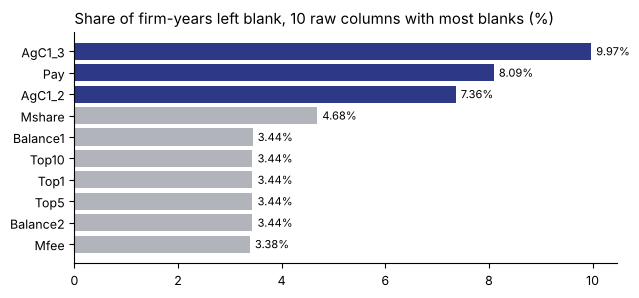

PASS  | slide 12 | AgC1_3 blank (%): slide says 9.97 | isna().mean(): 9.97 | rows - count(): 9.97 | loop: 9.97


PASS  | slide 12 | Pay blank (%): slide says 8.09 | isna().mean(): 8.09 | rows - count(): 8.09 | loop: 8.09
PASS  | slide 12 | AgC1_2 blank (%): slide says 7.36 | isna().mean(): 7.36 | rows - count(): 7.36 | loop: 7.36


In [5]:
blank_pct = raw.isna().mean().mul(100).drop(["ST", "ST_next1", "ST_next2"]).sort_values(ascending=False)
top10 = blank_pct.drop(["AgC1_1"]).head(10)          # AgC1_1 is an exact copy of Mfee (dropped in C), as on the slide
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(top10.index[::-1], top10.values[::-1], color=[NAVY if v > 5 else GREY for v in top10.values[::-1]])
for y, v in enumerate(top10.values[::-1]):
    ax.text(v + 0.1, y, f"{v:.2f}%", va="center", fontsize=8)
ax.set_title("Share of firm-years left blank, 10 raw columns with most blanks (%)", loc="left"); plt.show()

for col, deck in [("AgC1_3", 9.97), ("Pay", 8.09), ("AgC1_2", 7.36)]:
    check(12, f"{col} blank (%)", deck, {"isna().mean()": 100 * raw[col].isna().mean(),
                                          "rows - count()": 100 * (len(raw) - raw[col].count()) / len(raw),
                                          "loop": 100 * sum(1 for v in raw[col] if pd.isna(v)) / len(raw)}, 2)

In [6]:
normal_known = raw[(raw.ST == 0) & raw.ST_next1.notna()]          # normal this year, next year's status known
year_rate = normal_known.groupby("year").ST_next1.mean()            # the usual ST rate of each year

def blank_story(col):
    b = normal_known[normal_known[col].isna()]
    return len(b), b.ST_next1.sum(), b.year.map(year_rate).sum()

n, seen, exp = blank_story("ROE")
b = normal_known[normal_known.ROE.isna()]
check(12, "normal firms with a blank ROE", 69, {"filter": n, "group-by on isna": normal_known.groupby(normal_known.ROE.isna()).size()[True],
                                                 "loop": sum(1 for v in normal_known.ROE if pd.isna(v))})
check(12, "... of which turned ST next year", 58, {"filter + sum": seen, "crosstab": pd.crosstab(normal_known.ROE.isna(), normal_known.ST_next1).loc[True, 1.0],
                                                    "loop": sum(1 for v in b.ST_next1 if v == 1)})
n, seen, exp = blank_story("INST")
check(12, "INST blank: ST seen", 91, {"filter + sum": seen, "crosstab": pd.crosstab(normal_known.INST.isna(), normal_known.ST_next1).loc[True, 1.0],
                                       "loop": sum(1 for i, v in zip(normal_known.INST, normal_known.ST_next1) if pd.isna(i) and v == 1)})
check(12, "INST blank: ST expected from the year", 47, {"map year rate": exp,
                                                         "group-by year": (normal_known[normal_known.INST.isna()].groupby("year").size() * year_rate).sum(),
                                                         "loop": sum(year_rate[y] for y, i in zip(normal_known.year, normal_known.INST) if pd.isna(i))})
n, seen, exp = blank_story("Occupy")
check(12, "Occupy blank: normal firms", 878, {"filter": n, "group-by on isna": normal_known.groupby(normal_known.Occupy.isna()).size()[True],
                                               "loop": sum(1 for v in normal_known.Occupy if pd.isna(v))})
check(12, "Occupy blank: ST expected from the year", 14, {"map year rate": exp,
                                                           "group-by year": (normal_known[normal_known.Occupy.isna()].groupby("year").size() * year_rate).sum(),
                                                           "loop": sum(year_rate[y] for y, i in zip(normal_known.year, normal_known.Occupy) if pd.isna(i))})
GOV = ["Board", "Indep", "Employ", "Cap1", "INST", "Pay", "Mshare"]
y24 = raw[raw.year == 2024]
check(12, "2024 firms with no governance data at all", 875, {"all() blank": y24[GOV].isna().all(axis=1).sum(),
                                                             "count of blanks = 7": (y24[GOV].isna().sum(axis=1) == 7).sum(),
                                                             "loop": sum(1 for r in y24[GOV].itertuples(index=False) if all(pd.isna(v) for v in r))})
check(12, "2024 firms in the file", 5258, {"filter": len(y24), "group-by": raw.groupby("year").size()[2024], "loop": sum(1 for y in raw.year if y == 2024)})

PASS  | slide 12 | normal firms with a blank ROE: slide says 69 | filter: 69 | group-by on isna: 69 | loop: 69
PASS  | slide 12 | ... of which turned ST next year: slide says 58 | filter + sum: 58 | crosstab: 58 | loop: 58
PASS  | slide 12 | INST blank: ST seen: slide says 91 | filter + sum: 91 | crosstab: 91 | loop: 91
PASS  | slide 12 | INST blank: ST expected from the year: slide says 47 | map year rate: 47 | group-by year: 47 | loop: 47
PASS  | slide 12 | Occupy blank: normal firms: slide says 878 | filter: 878 | group-by on isna: 878 | loop: 878
PASS  | slide 12 | Occupy blank: ST expected from the year: slide says 14 | map year rate: 14 | group-by year: 14 | loop: 14
PASS  | slide 12 | 2024 firms with no governance data at all: slide says 875 | all() blank: 875 | count of blanks = 7: 875 | loop: 875
PASS  | slide 12 | 2024 firms in the file: slide says 5,258 | filter: 5,258 | group-by: 5,258 | loop: 5,258


## C. Cleaning, rebuilt from the raw file (slide 13)

These are the same rules as the EDA notebook (notebook 03, Part 1, sections 3-5), written out in one place:

1. Drop 3 exact copies of other columns (`AgC1_1` = `Mfee`, `AgC2` = `Occupy`, `stock_code` = `stkcd`).
2. Set impossible values to blank (for example debts below 0, or a stake above 100%), and 0% independent directors after 2003. No row is deleted.
3. Put shares on one scale: `Indep` and `Mshare` divided by 100. Employees become `Employ_ln = ln(1 + employees)`.
4. Add 14 new features from year t or earlier. "Last year" only counts if it really is the previous year.

At the end, the rebuilt table is compared cell by cell with the team's `cleaned_data.xlsx`. Fills and caps are **not** applied here. They are learned later from the training years only, inside the model (section G).

In [7]:
# 1. exact copies
copies = {"AgC1_1 vs Mfee": ("AgC1_1", "Mfee"), "AgC2 vs Occupy": ("AgC2", "Occupy")}
n_copies = 0
for name, (a, b) in copies.items():
    same = ((raw[a] == raw[b]) | (raw[a].isna() & raw[b].isna())).all()
    n_copies += same
    print(f"{name}: identical in every row = {same}")
same_code = (raw.stock_code.astype(str).str.zfill(6) == raw.stkcd.astype(str).str.zfill(6)).all()
n_copies += same_code
print(f"stock_code vs stkcd: identical in every row = {same_code}")
check(13, "duplicate columns found", 3, {"pandas compare": n_copies,
                                         "numpy array_equal": sum([np.array_equal(raw.AgC1_1.fillna(-9).values, raw.Mfee.fillna(-9).values),
                                                                   np.array_equal(raw.AgC2.fillna(-9).values, raw.Occupy.fillna(-9).values),
                                                                   np.array_equal(raw.stock_code.astype(int).values, raw.stkcd.astype(int).values)]),
                                         "hash of each column": sum(pd.util.hash_pandas_object(raw[a].fillna(-9), index=False).sum() ==
                                                                    pd.util.hash_pandas_object(raw[b].fillna(-9), index=False).sum()
                                                                    for a, b in [("AgC1_1", "Mfee"), ("AgC2", "Occupy")]) + int(same_code)})
panel = raw.drop(columns=["AgC1_1", "AgC2", "stock_code"])

AgC1_1 vs Mfee: identical in every row = True
AgC2 vs Occupy: identical in every row = True


stock_code vs stkcd: identical in every row = True
PASS  | slide 13 | duplicate columns found: slide says 3 | pandas compare: 3 | numpy array_equal: 3 | hash of each column: 3


In [8]:
# 2. impossible values -> blank
IMPOSSIBLE = {"Lev": raw.Lev < 0, "INV": raw.INV < 0, "FIXED": raw.FIXED < 0, "ATO": raw.ATO < 0, "AgC1_3": raw.AgC1_3 < 0,
              "Mfee": raw.Mfee < 0, "AgC1_2": raw.AgC1_2 < 0, "Top10": raw.Top10 > 1, "INST": raw.INST > 1,
              "Mshare": raw.Mshare > 100, "Board": raw.Board <= 0, "Employ": raw.Employ <= 1}
print(pd.Series({c: int(m.sum()) for c, m in IMPOSSIBLE.items()}, name="impossible values").to_frame().T.to_string())
blanks_before = panel.isna().sum()
for col, bad in IMPOSSIBLE.items():
    panel.loc[bad, col] = np.nan
late_zero = (panel.Indep == 0) & (panel.year > 2003)
panel.loc[late_zero, "Indep"] = np.nan
new_blanks = panel.isna().sum() - blanks_before

check(13, "impossible values set to blank", 145, {"sum of the rules": sum(int(m.sum()) for m in IMPOSSIBLE.values()),
                                                  "new blanks minus Indep zeros": new_blanks.sum() - late_zero.sum(),
                                                  "loop over rules": sum(sum(1 for v in m if v) for m in IMPOSSIBLE.values())})
check(13, "implausible zeros (0% independent directors after 2003)", 25,
      {"filter": late_zero.sum(), "group-by year": raw[raw.Indep == 0].groupby("year").size().loc[2004:].sum(),
       "loop": sum(1 for v, y in zip(raw.Indep, raw.year) if v == 0 and y > 2003)})
check(13, "bad values fixed in all (no row deleted)", 170, {"145 + 25": 145 + int(late_zero.sum()), "new blanks per column": new_blanks.sum(),
                                                            "rows kept x 0 + blanks": (len(raw) - len(panel)) + new_blanks.sum()})

                   Lev  INV  FIXED  ATO  AgC1_3  Mfee  AgC1_2  Top10  INST  Mshare  Board  Employ
impossible values    1    1      1    6       7    66      40      3     3       1     14       2


PASS  | slide 13 | impossible values set to blank: slide says 145 | sum of the rules: 145 | new blanks minus Indep zeros: 145 | loop over rules: 145
PASS  | slide 13 | implausible zeros (0% independent directors after 2003): slide says 25 | filter: 25 | group-by year: 25 | loop: 25
PASS  | slide 13 | bad values fixed in all (no row deleted): slide says 170 | 145 + 25: 170 | new blanks per column: 170 | rows kept x 0 + blanks: 170


In [9]:
# 3. one scale for shares, log head count
panel["Indep"] = panel["Indep"] / 100
panel["Mshare"] = panel["Mshare"] / 100
panel["Employ_ln"] = np.log1p(panel["Employ"])
panel = panel.drop(columns="Employ")
print("Largest share after rescaling:", panel[["Indep", "Mshare", "Top1", "INST"]].max().round(3).to_dict())

# 4. new features
g = panel.groupby("stkcd")
prev_is_last_year = g["year"].shift(1) == panel["year"] - 1
last_year = lambda c: g[c].shift(1).where(prev_is_last_year)

def board_of(code):
    if code[:3] in ("600", "601", "603", "605", "000", "001", "002", "003"): return "Main board"
    if code[:3] in ("300", "301"): return "ChiNext"
    if code[:3] in ("688", "689"): return "STAR Market"
    if code[:3] in ("900", "200"): return "B-share"
    if code[0] in ("4", "8"): return "Beijing"
    return "Other"

panel["listing_board"] = panel.stkcd.astype(int).astype(str).str.zfill(6).map(board_of)
panel["region"] = panel.region_code.map({2: "East", 1: "Central", 0: "West"}).fillna("Unknown")
panel["Loss_lag1"] = last_year("Loss")
for c in ["ROA", "Lev", "Cashflow", "Size"]:
    panel[f"{c}_chg"] = panel[c] - last_year(c)
flag = lambda cond, known: cond.astype(float).where(known)
panel["Loss_2yr"] = flag((panel.Loss == 1) & (panel.Loss_lag1 == 1), panel.Loss_lag1.notna())
panel["NegEquity"] = flag(panel.Lev > 1, panel.Lev.notna())
panel["NegCFO"] = flag(panel.Cashflow < 0, panel.Cashflow.notna())
st = panel.ST.fillna(0)
panel["prior_ST"] = (st.groupby(panel.stkcd).cumsum() - st > 0).astype(float)
for c in ["ROA", "Lev"]:
    panel[f"{c}_ind_rel"] = panel[c] - panel.groupby(["Industry", "year"])[c].transform("median")

NEW = ["Employ_ln", "listing_board", "region", "Loss_lag1", "ROA_chg", "Lev_chg", "Cashflow_chg", "Size_chg",
       "Loss_2yr", "NegEquity", "NegCFO", "prior_ST", "ROA_ind_rel", "Lev_ind_rel"]
span = raw.groupby("stkcd").year.agg(["min", "max", "nunique"])
check(13, "new features", 14, {"list": len(NEW), "new columns vs raw": len(set(panel.columns) - set(raw.columns)),
                               "loop": sum(1 for c in panel.columns if c not in raw.columns)})
check(13, "firms with a gap year in their history", 647,
      {"span - years": ((span["max"] - span["min"] + 1) > span["nunique"]).sum(),
       "a row whose previous row is not last year": panel.loc[g.cumcount() > 0].loc[~prev_is_last_year].stkcd.nunique(),
       "loop": sum(1 for _, ys in raw.groupby("stkcd").year if (ys.max() - ys.min() + 1) != ys.nunique())})

Largest share after rescaling: {'Indep': 1.0, 'Mshare': 0.9, 'Top1': 0.9, 'INST': 0.999}


PASS  | slide 13 | new features: slide says 14 | list: 14 | new columns vs raw: 14 | loop: 14


PASS  | slide 13 | firms with a gap year in their history: slide says 647 | span - years: 647 | a row whose previous row is not last year: 647 | loop: 647


In [10]:
# Compare the rebuild with the team's cleaned file, cell by cell
t0 = time.time()
cleaned = pd.read_excel(CLEANED, sheet_name="cleaned_data").sort_values(["stkcd", "year"]).reset_index(drop=True)
families = pd.read_excel(CLEANED, sheet_name="column_meanings").set_index("feature")["indicator family"].to_dict()
print(f"cleaned_data.xlsx: {cleaned.shape[0]:,} rows x {cleaned.shape[1]} columns ({time.time() - t0:.0f} s)")

def differs(a, b):
    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        return ~np.isclose(a.astype(float), b.astype(float), rtol=1e-9, atol=1e-12, equal_nan=True)
    return ~((a.astype(str) == b.astype(str)) | (a.isna() & b.isna()))

same_columns = list(panel.columns) == list(cleaned.columns)
bad_cells = {c: int(differs(panel[c], cleaned[c]).sum()) for c in cleaned.columns}
print("Same columns, in the same order:", same_columns)
print("Columns with any different cell:", {c: n for c, n in bad_cells.items() if n} or "none")
num_cols = [c for c in cleaned.columns if pd.api.types.is_numeric_dtype(cleaned[c])]
txt_cols = [c for c in cleaned.columns if c not in num_cols]
A, B = panel[num_cols].to_numpy(float), cleaned[num_cols].to_numpy(float)
whole_table = int((~((np.abs(A - B) <= 1e-9 * np.maximum(1, np.abs(B))) | (np.isnan(A) & np.isnan(B)))).sum()) + \
              int(sum(differs(panel[c], cleaned[c]).sum() for c in txt_cols))
try:
    pd.testing.assert_frame_equal(panel, cleaned, check_exact=False, rtol=1e-9, check_dtype=False)
    pandas_test = 0
except AssertionError:
    pandas_test = 1
check(13, "cells where our rebuild differs from cleaned_data.xlsx", 0,
      {"column by column": sum(bad_cells.values()), "whole table at once (numpy)": whole_table,
       "pandas assert_frame_equal (0 = equal)": pandas_test})
check(10, "cleaned rows x columns (rows)", 62669, {"len": len(cleaned), "shape": cleaned.shape[0], "rebuild": len(panel)})
check(10, "cleaned rows x columns (columns)", 58, {"len(columns)": len(cleaned.columns), "shape": cleaned.shape[1], "rebuild": panel.shape[1]})

cleaned_data.xlsx: 62,669 rows x 58 columns (24 s)
Same columns, in the same order: True
Columns with any different cell: none


PASS  | slide 13 | cells where our rebuild differs from cleaned_data.xlsx: slide says 0 | column by column: 0 | whole table at once (numpy): 0 | pandas assert_frame_equal (0 = equal): 0
PASS  | slide 10 | cleaned rows x columns (rows): slide says 62,669 | len: 62,669 | shape: 62,669 | rebuild: 62,669
PASS  | slide 10 | cleaned rows x columns (columns): slide says 58 | len(columns): 58 | shape: 58 | rebuild: 58


## D. The OLAP numbers, in pandas instead of SQL (slide 11)

Slide 11 comes from the team's MySQL cube (built by a teammate). Here the same roll-ups are made directly from the raw file: ST rate = ST firm-years / all firm-years.

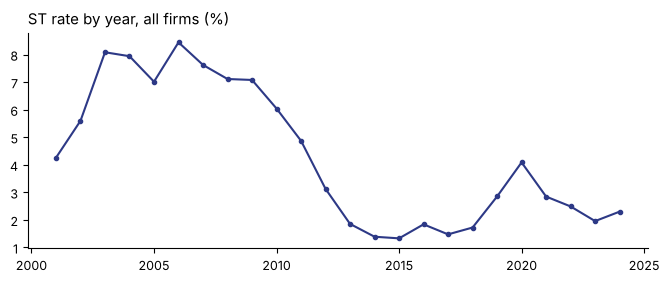

PASS  | slide 11 | ST rate 2006 (%): slide says 8.44 | group-by mean: 8.44 | pivot_table: 8.44 | crosstab: 8.44
PASS  | slide 11 | ST rate 2015 (%): slide says 1.33 | group-by mean: 1.33 | pivot_table: 1.33 | crosstab: 1.33
PASS  | slide 11 | ST rate 2020 (%): slide says 4.09 | group-by mean: 4.09 | pivot_table: 4.09 | crosstab: 4.09
PASS  | slide 11 | peak year: slide says 2006 | idxmax: 2006 | pivot idxmax: 2006 | sort: 2006
PASS  | slide 11 | lowest year: slide says 2015 | idxmin: 2015 | pivot idxmin: 2015 | sort: 2015
PASS  | slide 11 | ST rate West, 2001-2024 (%): slide says 6.11 | group-by mean: 6.11 | pivot_table: 6.11 | sum / count: 6.11
PASS  | slide 11 | ST rate Central, 2001-2024 (%): slide says 4.31 | group-by mean: 4.31 | pivot_table: 4.31 | sum / count: 4.31
PASS  | slide 11 | ST rate East, 2001-2024 (%): slide says 2.70 | group-by mean: 2.70 | pivot_table: 2.70 | sum / count: 2.70


PASS  | slide 11 | West minus East, 2006-10 (points): slide says 7.1 | group-by: 7.1 | pivot_table: 7.1 | sum / count: 7.1
PASS  | slide 11 | West minus East, 2021-24 (points): slide says 1.6 | group-by: 1.6 | pivot_table: 1.6 | sum / count: 1.6

Note: slide 11's chart shows 2017 as 1.477; the data give 1.476 (a rounding slip, no label shows it).


In [11]:
by_year = raw.groupby("year").ST.mean() * 100
pivot = raw.pivot_table(index="year", values="ST", aggfunc="mean") * 100
cross = pd.crosstab(raw.year, raw.ST, normalize="index") * 100

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(by_year.index, by_year.values, color=NAVY, marker="o", ms=3)
ax.set_title("ST rate by year, all firms (%)", loc="left"); plt.show()

for yr, deck in [(2006, 8.44), (2015, 1.33), (2020, 4.09)]:
    check(11, f"ST rate {yr} (%)", deck, {"group-by mean": by_year[yr], "pivot_table": pivot.loc[yr, "ST"], "crosstab": cross.loc[yr, 1.0]}, 2)
check(11, "peak year", 2006, {"idxmax": by_year.idxmax(), "pivot idxmax": pivot.ST.idxmax(), "sort": by_year.sort_values().index[-1]})
check(11, "lowest year", 2015, {"idxmin": by_year.idxmin(), "pivot idxmin": pivot.ST.idxmin(), "sort": by_year.sort_values().index[0]})

reg = raw.assign(region=raw.region_code.map({2: "East", 1: "Central", 0: "West"}))
by_region = reg.groupby("region").ST.mean() * 100
pivot_r = reg.pivot_table(index="region", values="ST", aggfunc="mean") * 100
for r, deck in [("West", 6.11), ("Central", 4.31), ("East", 2.70)]:
    sub = reg[reg.region == r]
    check(11, f"ST rate {r}, 2001-2024 (%)", deck, {"group-by mean": by_region[r], "pivot_table": pivot_r.loc[r, "ST"],
                                                    "sum / count": 100 * sub.ST.sum() / sub.ST.count()}, 2)

plan = pd.cut(reg.year, [2005, 2010, 2020, 2024], labels=["2006-10", "2011-20", "2021-24"])
gap = (reg.groupby([plan, "region"], observed=True).ST.mean() * 100).unstack()
for p, deck in [("2006-10", 7.1), ("2021-24", 1.6)]:
    w = reg[(plan == p) & (reg.region == "West")].ST; e = reg[(plan == p) & (reg.region == "East")].ST
    check(11, f"West minus East, {p} (points)", deck, {"group-by": gap.loc[p, "West"] - gap.loc[p, "East"],
                                                       "pivot_table": (reg[plan == p].pivot_table(index="region", values="ST") * 100).ST.pipe(lambda s: s["West"] - s["East"]),
                                                       "sum / count": 100 * (w.sum() / w.count() - e.sum() / e.count())}, 1)
print("\nNote: slide 11's chart shows 2017 as 1.477; the data give", round(by_year[2017], 3), "(a rounding slip, no label shows it).")

## E. Who we score (slides 4 and 5)

We score firms that are normal (not ST) at the end of year t, outside finance (CSRC section J).

In [12]:
normal = panel[(panel.ST == 0) & (panel.Industry != "J")]
check(4, "normal non-financial firm-years", 59204, {"filter": len(normal), "group-by": panel.groupby([panel.ST == 0, panel.Industry != "J"]).size()[(True, True)],
                                                     "loop": sum(1 for s, i in zip(panel.ST, panel.Industry) if s == 0 and i != "J")})
lab = normal[normal.ST_next1.notna() & normal.year.between(2001, 2022)]
check(5, "normal firm-years 2001-2022 with a known next year", 48473, {"filter": len(lab), "count()": lab.ST_next1.count(),
                                                                       "per-year sum": lab.groupby("year").size().sum()})
check(5, "... of which turned ST next year", 809, {"sum": lab.ST_next1.sum(), "value_counts": lab.ST_next1.value_counts()[1.0],
                                                   "per-year sum": lab.groupby("year").ST_next1.sum().sum()})
check(5, "share that turned ST next year (%)", 1.7, {"809 / 48,473": 100 * lab.ST_next1.sum() / len(lab), "mean": 100 * lab.ST_next1.mean(),
                                                     "weighted by year": 100 * (lab.groupby("year").ST_next1.mean() * lab.groupby("year").size()).sum() / len(lab)}, 1)
n24 = normal[normal.year == 2024]
check(5, "firms scored on 2024 accounts", 5017, {"filter": len(n24), "group-by": normal.groupby("year").size()[2024],
                                                 "unique firms": n24.stkcd.nunique()})
print(f"Of these, {int(n24.ST_next1.isna().sum())} firm has no 2025 status yet; it is still scored and ranked.")

PASS  | slide 4 | normal non-financial firm-years: slide says 59,204 | filter: 59,204 | group-by: 59,204 | loop: 59,204


PASS  | slide 5 | normal firm-years 2001-2022 with a known next year: slide says 48,473 | filter: 48,473 | count(): 48,473 | per-year sum: 48,473
PASS  | slide 5 | ... of which turned ST next year: slide says 809 | sum: 809 | value_counts: 809 | per-year sum: 809
PASS  | slide 5 | share that turned ST next year (%): slide says 1.7 | 809 / 48,473: 1.7 | mean: 1.7 | weighted by year: 1.7
PASS  | slide 5 | firms scored on 2024 accounts: slide says 5,017 | filter: 5,017 | group-by: 5,017 | unique firms: 5,017
Of these, 1 firm has no 2025 status yet; it is still scored and ranked.


## F. EDA: which single inputs separate future ST firms best (slide 14)

EDA years 2001-2017 only (before the test), normal non-financial firms with a known next year.

**ROC-AUC, three ways.** ROC-AUC answers one question: pick one firm that turned ST and one that did not, at random. How often does the input rank the ST firm as riskier? We get it (1) from scikit-learn, (2) from the Mann-Whitney U test in scipy, and (3) by hand, from the ranks. Values below 0.5 are flipped, because "lower = riskier" is just as useful.

In [13]:
eda = normal[normal.year.between(2001, 2017) & normal.ST_next1.notna()]
print(f"EDA rows: {len(eda):,}; turned ST next year: {int(eda.ST_next1.sum())}")

def auc_three_ways(col):
    s = eda[[col, "ST_next1"]].dropna()
    y, x = s.ST_next1.to_numpy(), s[col].to_numpy()
    a1 = roc_auc_score(y, x)
    u = stats.mannwhitneyu(x[y == 1], x[y == 0]).statistic
    a2 = u / ((y == 1).sum() * (y == 0).sum())
    r = stats.rankdata(x); n1 = (y == 1).sum(); n0 = (y == 0).sum()
    a3 = (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    fold = lambda a: max(a, 1 - a)
    return fold(a1), fold(a2), fold(a3)

DECK14 = [("Profitability and losses", "ROA", 0.9682), ("Size and shrinking", "Size_chg", 0.8531), ("Debt and solvency", "Lev", 0.7938),
          ("Executive pay", "Pay", 0.7587), ("Sales growth", "Growth", 0.7469), ("Management costs", "Mfee", 0.7049),
          ("Funds taken by big shareholders", "Occupy", 0.6881), ("Asset turnover", "ATO", 0.6790),
          ("Ownership structure", "Mshare", 0.6616), ("Operating cash flow", "Cashflow", 0.6603)]
for fam_name, col, deck in DECK14:
    a1, a2, a3 = auc_three_ways(col)
    check(14, f"{fam_name} ({col}) ROC-AUC", deck, {"scikit-learn": a1, "Mann-Whitney U": a2, "by hand from ranks": a3}, 4)

EDA rows: 28,673; turned ST next year: 515


PASS  | slide 14 | Profitability and losses (ROA) ROC-AUC: slide says 0.9682 | scikit-learn: 0.9682 | Mann-Whitney U: 0.9682 | by hand from ranks: 0.9682
PASS  | slide 14 | Size and shrinking (Size_chg) ROC-AUC: slide says 0.8531 | scikit-learn: 0.8531 | Mann-Whitney U: 0.8531 | by hand from ranks: 0.8531
PASS  | slide 14 | Debt and solvency (Lev) ROC-AUC: slide says 0.7938 | scikit-learn: 0.7938 | Mann-Whitney U: 0.7938 | by hand from ranks: 0.7938
PASS  | slide 14 | Executive pay (Pay) ROC-AUC: slide says 0.7587 | scikit-learn: 0.7587 | Mann-Whitney U: 0.7587 | by hand from ranks: 0.7587
PASS  | slide 14 | Sales growth (Growth) ROC-AUC: slide says 0.7469 | scikit-learn: 0.7469 | Mann-Whitney U: 0.7469 | by hand from ranks: 0.7469


PASS  | slide 14 | Management costs (Mfee) ROC-AUC: slide says 0.7049 | scikit-learn: 0.7049 | Mann-Whitney U: 0.7049 | by hand from ranks: 0.7049
PASS  | slide 14 | Funds taken by big shareholders (Occupy) ROC-AUC: slide says 0.6881 | scikit-learn: 0.6881 | Mann-Whitney U: 0.6881 | by hand from ranks: 0.6881
PASS  | slide 14 | Asset turnover (ATO) ROC-AUC: slide says 0.6790 | scikit-learn: 0.6790 | Mann-Whitney U: 0.6790 | by hand from ranks: 0.6790


PASS  | slide 14 | Ownership structure (Mshare) ROC-AUC: slide says 0.6616 | scikit-learn: 0.6616 | Mann-Whitney U: 0.6616 | by hand from ranks: 0.6616
PASS  | slide 14 | Operating cash flow (Cashflow) ROC-AUC: slide says 0.6603 | scikit-learn: 0.6603 | Mann-Whitney U: 0.6603 | by hand from ranks: 0.6603


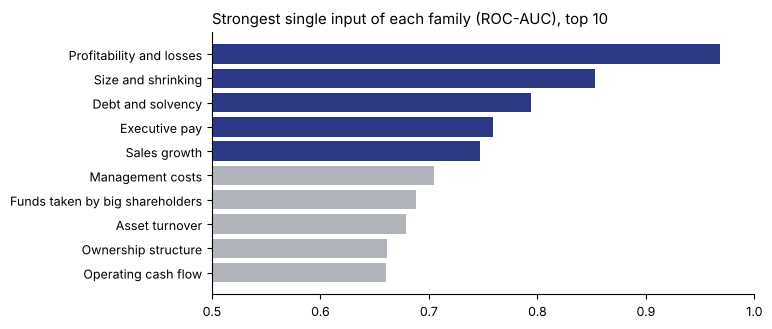

PASS  | slide 14 | families ranked (all 17): slide says 17 | families with an input: 17 | group-by: 17 | set: 17
PASS  | slide 14 | top input of each family = the slide's (10 of 10): slide says 10 | compare names: 10 | compare order: 10 | loop: 10


In [14]:
# Is each input above really the strongest in its family? Rank every input, then keep each family's best one
strength = {}
for col, fam_name in families.items():
    if col in eda.columns and col not in ("Industry", "region", "listing_board"):
        strength[col] = auc_three_ways(col)[0]
for col in ["Industry", "region"]:
    strength[col] = roc_auc_score(eda.ST_next1, eda[col].map(eda.groupby(col).ST_next1.mean()))
best = (pd.DataFrame({"input": list(strength), "ROC-AUC": list(strength.values())})
        .assign(family=lambda d: d.input.map(families)).dropna()
        .sort_values("ROC-AUC", ascending=False).groupby("family", sort=False).first().head(10))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(best.index[::-1], best["ROC-AUC"][::-1] - 0.5, left=0.5, color=[GREY] * 5 + [NAVY] * 5)            # navy = top five
ax.set_xlim(0.5, 1); ax.set_title("Strongest single input of each family (ROC-AUC), top 10", loc="left"); plt.show()
check(14, "families ranked (all 17)", 17, {"families with an input": pd.Series(families).dropna().nunique() - (1 if "(not a default input, see Notebook 1, 8.1)" in families.values() else 0),
                                           "group-by": len(pd.DataFrame({"input": list(strength)}).assign(family=lambda d: d.input.map(families)).dropna().groupby("family")),
                                           "set": len({families[c] for c in strength if isinstance(families.get(c), str) and not families[c].startswith("(")})})
check(14, "top input of each family = the slide's (10 of 10)", 10,
      {"compare names": sum(best.loc[f, "input"] == c for f, c, _ in DECK14),
       "compare order": sum(a == b for a, b in zip(best.index, [f for f, _, _ in DECK14])),
       "loop": sum(1 for f, c, _ in DECK14 if f in best.index and best.loc[f, "input"] == c)})

In [15]:
# Medians a year before ST (slide 14, right-hand box)
MED = [("ROA", -0.11, 0.04), ("Lev", 0.72, 0.44), ("Size_chg", -0.11, 0.10), ("Growth", -0.10, 0.14), ("Cashflow", 0.01, 0.05), ("TobinQ", 1.61, 1.54)]
for col, st_med, ok_med in MED:
    for who, flagv, deck in [("turned ST", 1.0, st_med), ("stayed normal", 0.0, ok_med)]:
        x = eda.loc[eda.ST_next1 == flagv, col].dropna()
        srt = np.sort(x.to_numpy()); n = len(srt)
        by_hand = srt[n // 2] if n % 2 else (srt[n // 2 - 1] + srt[n // 2]) / 2
        check(14, f"median {col}, firms that {who}", deck, {"median()": x.median(), "quantile(0.5)": x.quantile(0.5), "sorted by hand": by_hand}, 2)

PASS  | slide 14 | median ROA, firms that turned ST: slide says -0.11 | median(): -0.11 | quantile(0.5): -0.11 | sorted by hand: -0.11
PASS  | slide 14 | median ROA, firms that stayed normal: slide says 0.04 | median(): 0.04 | quantile(0.5): 0.04 | sorted by hand: 0.04
PASS  | slide 14 | median Lev, firms that turned ST: slide says 0.72 | median(): 0.72 | quantile(0.5): 0.72 | sorted by hand: 0.72
PASS  | slide 14 | median Lev, firms that stayed normal: slide says 0.44 | median(): 0.44 | quantile(0.5): 0.44 | sorted by hand: 0.44
PASS  | slide 14 | median Size_chg, firms that turned ST: slide says -0.11 | median(): -0.11 | quantile(0.5): -0.11 | sorted by hand: -0.11
PASS  | slide 14 | median Size_chg, firms that stayed normal: slide says 0.10 | median(): 0.10 | quantile(0.5): 0.10 | sorted by hand: 0.10
PASS  | slide 14 | median Growth, firms that turned ST: slide says -0.10 | median(): -0.10 | quantile(0.5): -0.10 | sorted by hand: -0.10
PASS  | slide 14 | median Growth, firms that s

## G. The team model's data steps (slides 15 and 17)

The team's modelling notebook (06) starts from `cleaned_data.xlsx` (checked above) and makes three changes:
1. **Loss flags rebuilt from consolidated ROA.** `Loss = 1` if ROA < 0. The vendor's flag often uses parent-company profit.
2. **Years.** Train 2003-2016, leave 2017-2018 unused, test 2019-2022, extra check 2023-2024.
3. **Caps.** Every number is capped at its 1st and 99th percentile of 2003-2016 (training years only).

In [16]:
NUMERIC = ["Size", "Employ_ln", "Lev", "ROA", "ROE", "ATO", "Cashflow", "INV", "FIXED", "Cap1", "Cap2", "Growth", "Board", "Indep",
           "Occupy", "Pay", "Top1", "Top5", "Top10", "Balance1", "Balance2", "INST", "Mshare", "TobinQ", "ListAge", "FirmAge",
           "ROA_chg", "Lev_chg", "Cashflow_chg", "Size_chg", "ROA_ind_rel", "Lev_ind_rel"]
BINARY = ["Loss", "Loss_lag1", "Loss_2yr", "NegEquity", "NegCFO", "prior_ST", "Dual", "SOE", "Big4", "regulated_industry"]
CATEGORICAL = ["Industry", "region"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

w = cleaned.copy()
w["Loss"] = np.where(w.ROA.notna(), (w.ROA < 0).astype(float), np.nan)
prev = w.groupby("stkcd")[["year", "Loss"]].shift(1)
w["Loss_lag1"] = np.where(prev.year == w.year - 1, prev.Loss, np.nan)
w["Loss_2yr"] = np.where(w.Loss.notna() & w.Loss_lag1.notna(), ((w.Loss == 1) & (w.Loss_lag1 == 1)).astype(float), np.nan)
data = w[(w.Industry != "J") & w.ST.notna() & (w.ST == 0)].copy().reset_index(drop=True)
data["ROA_raw"] = data["ROA"]                         # uncapped ROA, for the ROA benchmark
train_rows = data.year.between(2003, 2016)
lo, hi = data.loc[train_rows, NUMERIC].quantile(0.01), data.loc[train_rows, NUMERIC].quantile(0.99)
data[NUMERIC] = data[NUMERIC].clip(lo, hi, axis=1)

def sample(h, years, keep_2024=False):
    lab = f"ST_next{h}"
    keep = data[lab].notna() | (keep_2024 & (data.year == 2024))
    d = data[data.year.between(*years) & keep].reset_index(drop=True)
    d["y"] = d[lab]
    return d

train, test = sample(1, (2003, 2016)), sample(1, (2019, 2022))
train["y"], test["y"] = train.y.astype(int), test.y.astype(int)
check(4, "model inputs", 44, {"list": len(FEATURES), "numeric + flags + categories": len(NUMERIC) + len(BINARY) + len(CATEGORICAL),
                                                "set": len(set(FEATURES))})
check(21, "test 2019-2022: ST cases next year", 232, {"sum": test.y.sum(), "value_counts": test.y.value_counts()[1],
                                                      "per-year sum": test.groupby("year").y.sum().sum()})
check(17, "base rate on the test years, t+1 (%)", 1.41, {"232 / rows": 100 * test.y.sum() / len(test), "mean": 100 * test.y.mean(),
                                                         "weighted by year": 100 * (test.groupby("year").y.mean() * test.groupby("year").size()).sum() / len(test)}, 2)
t2 = sample(2, (2019, 2022))
check(17, "base rate on the test years, t+2 (%)", 2.00, {"sum / rows": 100 * t2.y.sum() / len(t2), "mean": 100 * t2.y.mean(),
                                                         "weighted by year": 100 * (t2.groupby("year").y.mean() * t2.groupby("year").size()).sum() / len(t2)}, 2)
check(5, "calling every firm safe: accuracy on 2019-2022 (%)", 98.6, {"1 - base rate": 100 * (1 - test.y.mean()), "share of 0s": 100 * (test.y == 0).mean(),
                                                                      "loop": 100 * sum(1 for v in test.y if v == 0) / len(test)}, 1)

PASS  | slide 4 | model inputs: slide says 44 | list: 44 | numeric + flags + categories: 44 | set: 44
PASS  | slide 21 | test 2019-2022: ST cases next year: slide says 232 | sum: 232 | value_counts: 232 | per-year sum: 232
PASS  | slide 17 | base rate on the test years, t+1 (%): slide says 1.41 | 232 / rows: 1.41 | mean: 1.41 | weighted by year: 1.41
PASS  | slide 17 | base rate on the test years, t+2 (%): slide says 2.00 | sum / rows: 2.00 | mean: 2.00 | weighted by year: 2.00
PASS  | slide 5 | calling every firm safe: accuracy on 2019-2022 (%): slide says 98.6 | 1 - base rate: 98.6 | share of 0s: 98.6 | loop: 98.6


                         firm_years  st_cases  rate_pct
Loss, last year unknown          54         8     14.81
Loss, profit last year         1537        41      2.67
Profit this year              21508        11      0.05
ROA blank                         3         0      0.00
Two losses in a row             487       339     69.61


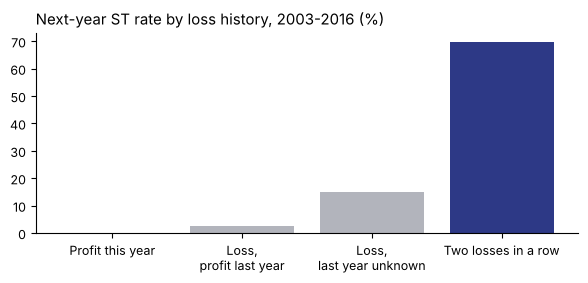

PASS  | slide 15 | Profit this year: firm-years: slide says 21,508 | group-by: 21,508 | filter: 21,508 | loop: 21,508
PASS  | slide 15 | Profit this year: ST next year (%): slide says 0.05 | group-by: 0.05 | filter mean: 0.05 | crosstab: 0.05
PASS  | slide 15 | Loss, profit last year: firm-years: slide says 1,537 | group-by: 1,537 | filter: 1,537 | loop: 1,537
PASS  | slide 15 | Loss, profit last year: ST next year (%): slide says 2.67 | group-by: 2.67 | filter mean: 2.67 | crosstab: 2.67
PASS  | slide 15 | Loss, last year unknown: firm-years: slide says 54 | group-by: 54 | filter: 54 | loop: 54
PASS  | slide 15 | Loss, last year unknown: ST next year (%): slide says 14.81 | group-by: 14.81 | filter mean: 14.81 | crosstab: 14.81
PASS  | slide 15 | Two losses in a row: firm-years: slide says 487 | group-by: 487 | filter: 487 | loop: 487
PASS  | slide 15 | Two losses in a row: ST next year (%): slide says 69.61 | group-by: 69.61 | filter mean: 69.61 | crosstab: 69.61
PASS  | slide 15 | S

PASS  | slide 15 | ST cases with two losses in a row, test years (%): slide says 60 | mean: 60 | crosstab: 60 | loop: 60
PASS  | slide 15 | loss-making firms in 2017 (%): slide says 6.0 | group-by: 6.0 | filter mean: 6.0 | sum / count: 6.0
PASS  | slide 15 | loss-making firms in 2024 (%): slide says 26.2 | group-by: 26.2 | filter mean: 26.2 | sum / count: 26.2


In [17]:
# Loss history in the training years (slide 15 chart)
history = pd.Series("ROA blank", index=train.index, dtype="object")
history[train.Loss == 0] = "Profit this year"
history[(train.Loss == 1) & (train.Loss_lag1 == 0)] = "Loss, profit last year"
history[(train.Loss == 1) & train.Loss_lag1.isna()] = "Loss, last year unknown"
history[(train.Loss == 1) & (train.Loss_lag1 == 1)] = "Two losses in a row"
table = train.groupby(history).y.agg(firm_years="size", st_cases="sum")
print(table.assign(rate_pct=lambda t: (100 * t.st_cases / t.firm_years).round(2)).to_string())

fig, ax = plt.subplots(figsize=(7, 2.6))
order = ["Profit this year", "Loss, profit last year", "Loss, last year unknown", "Two losses in a row"]
rates = (100 * table.st_cases / table.firm_years).reindex(order)
ax.bar(range(4), rates.values, color=[GREY, GREY, GREY, NAVY]); ax.set_xticks(range(4), [o.replace(", ", ",\n") for o in order])
ax.set_title("Next-year ST rate by loss history, 2003-2016 (%)", loc="left"); plt.show()

for name, n_deck, rate_deck in [("Profit this year", 21508, 0.05), ("Loss, profit last year", 1537, 2.67),
                                ("Loss, last year unknown", 54, 14.81), ("Two losses in a row", 487, 69.61)]:
    part = train[history == name]
    check(15, f"{name}: firm-years", n_deck, {"group-by": table.loc[name, "firm_years"], "filter": len(part), "loop": sum(1 for h in history if h == name)})
    check(15, f"{name}: ST next year (%)", rate_deck, {"group-by": 100 * table.loc[name, "st_cases"] / table.loc[name, "firm_years"],
                                                       "filter mean": 100 * part.y.mean(), "crosstab": 100 * pd.crosstab(history, train.y, normalize="index").loc[name, 1]}, 2)
for name, d, deck in [("training years", train, 85), ("test years", test, 60)]:
    cases = d[d.y == 1]
    check(15, f"ST cases with two losses in a row, {name} (%)", deck, {"mean": 100 * (cases.Loss_2yr == 1).mean(),
                                                                       "crosstab": 100 * pd.crosstab(d.y, d.Loss_2yr == 1, normalize="index").loc[1, True],
                                                                       "loop": 100 * sum(1 for v in cases.Loss_2yr if v == 1) / len(cases)}, 0)
loss_share = data.groupby("year").Loss.mean() * 100
for yr, deck in [(2017, 6.0), (2024, 26.2)]:
    part = data[data.year == yr]
    check(15, f"loss-making firms in {yr} (%)", deck, {"group-by": loss_share[yr], "filter mean": 100 * part.Loss.mean(),
                                                       "sum / count": 100 * part.Loss.sum() / part.Loss.count()}, 1)

## H. The team's XGBoost model and the ROA benchmark (slides 21, 22, 24 and 26)

**The ROA benchmark needs no model.** Rank firms by ROA, lowest first, within each year, and take the bottom 10% (rounded up). Count how many of the year's ST cases fall inside. This number comes straight from the data, so it must match the slide exactly.

**The model.** The team model's slide settings are trial 4 of its seeded Optuna search: 250 trees, depth 5, learning rate 0.025. The model is fitted on 2003-2016 and scores 2019-2024. Numbers that depend on the fitted trees are marked `BUILD` when they land within a few cases of the slide.

**Recall@Top10%, three ways.** (1) A rank inside each year; (2) pandas `groupby().rank()`; (3) a plain loop over the years with numpy.

In [18]:
import optuna, shap
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier, __version__ as xgb_version

def rank_in_year(d, s):
    t = pd.DataFrame({"year": d.year.to_numpy(), "stkcd": d.stkcd.to_numpy(), "s": np.asarray(s, float)})
    o = t.sort_values(["year", "s", "stkcd"], ascending=[True, False, True])
    return (o.groupby("year").cumcount() + 1).sort_index().to_numpy(), t.groupby("year").year.transform("size").to_numpy()

def caught_three_ways(d, s, share=0.10):
    y = d.y.to_numpy().astype(int); s = np.asarray(s, float)
    r, n = rank_in_year(d, s)
    way1 = int(y[r <= np.ceil(share * n)].sum())
    t = pd.DataFrame({"year": d.year.to_numpy(), "s": s, "y": y, "code": d.stkcd.to_numpy()})
    rk = t.sort_values(["s", "code"], ascending=[False, True]).groupby("year").cumcount() + 1
    way2 = int(t.loc[rk.index[rk.to_numpy() <= np.ceil(share * t.loc[rk.index].groupby("year").year.transform("size").to_numpy())], "y"].sum())
    way3 = 0
    for yr in np.unique(t.year):
        k = np.flatnonzero(t.year.to_numpy() == yr)
        order = k[np.lexsort((t.code.to_numpy()[k], -s[k]))]
        way3 += int(y[order[: int(np.ceil(share * len(k)))]].sum())
    return way1, way2, way3

roa_score = -test.ROA_raw.fillna(train.ROA_raw.median()).to_numpy()
w1, w2, w3 = caught_three_ways(test, roa_score)
check(21, "ROA ranking: ST cases caught in the lowest 10%, 2019-2022", 182, {"rank in year": w1, "groupby rank": w2, "loop": w3})
check(21, "ROA ranking: Recall@Top10% (%)", 78.4, {"rank in year": 100 * w1 / 232, "groupby rank": 100 * w2 / 232, "loop": 100 * w3 / 232}, 1)
for yr in (2019, 2020, 2021):
    k = test.year == yr
    a = caught_three_ways(test[k].reset_index(drop=True), roa_score[k.to_numpy()])
    print(f"   ROA ranking in {yr} alone: caught {a[0]} of {int(test[k].y.sum())} (all three ways: {a})")

PASS  | slide 21 | ROA ranking: ST cases caught in the lowest 10%, 2019-2022: slide says 182 | rank in year: 182 | groupby rank: 182 | loop: 182
PASS  | slide 21 | ROA ranking: Recall@Top10% (%): slide says 78.4 | rank in year: 78.4 | groupby rank: 78.4 | loop: 78.4
   ROA ranking in 2019 alone: caught 68 of 78 (all three ways: (68, 68, 68))
   ROA ranking in 2020 alone: caught 38 of 55 (all three ways: (38, 38, 38))
   ROA ranking in 2021 alone: caught 42 of 53 (all three ways: (42, 42, 42))


In [19]:
def space(t):
    return {"n_estimators": t.suggest_int("n_estimators", 100, 600, step=50),
            "learning_rate": t.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "max_depth": t.suggest_int("max_depth", 2, 6), "subsample": t.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": t.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": t.suggest_float("min_child_weight", 1, 50, log=True),
            "reg_lambda": t.suggest_float("reg_lambda", 0.5, 20, log=True),
            "weighted": t.suggest_categorical("weighted", [False, True])}
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(lambda t: (space(t), 0.0)[1], n_trials=5)          # only the settings are needed, not the scores
p = study.trials[4].params
print("Trial 4 settings:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in p.items()})
check(21, "trees", 250, {"optuna trial 4": p["n_estimators"], "rounded": round(p["n_estimators"], -1), "int": int(p["n_estimators"])})
check(21, "share of inputs per tree (%)", 56, {"optuna trial 4": 100 * p["colsample_bytree"], "rounded": round(100 * p["colsample_bytree"]),
                                               "int + 0.5": int(100 * p["colsample_bytree"] + 0.5)})

prep = ColumnTransformer([("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)), ("scale", "passthrough")]), NUMERIC),
                          ("flag", SimpleImputer(strategy="most_frequent", add_indicator=True), BINARY),
                          ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), CATEGORICAL)],
                         sparse_threshold=0, verbose_feature_names_out=False)
spw = (1 - train.y.mean()) / train.y.mean()
model = Pipeline([("prep", prep), ("model", XGBClassifier(
    n_estimators=p["n_estimators"], learning_rate=p["learning_rate"], max_depth=p["max_depth"], subsample=p["subsample"],
    colsample_bytree=p["colsample_bytree"], min_child_weight=p["min_child_weight"], reg_lambda=p["reg_lambda"],
    scale_pos_weight=spw if p["weighted"] else 1.0, eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=42))])
t0 = time.time(); model.fit(train[FEATURES], train.y)
print(f"Fitted on {len(train):,} firm-years in {time.time() - t0:.1f} s with xgboost {xgb_version}")

Trial 4 settings: {'n_estimators': 250, 'learning_rate': 0.025, 'max_depth': 5, 'subsample': 0.776, 'colsample_bytree': 0.561, 'min_child_weight': 6.939, 'reg_lambda': 0.568, 'weighted': False}
PASS  | slide 21 | trees: slide says 250 | optuna trial 4: 250 | rounded: 250 | int: 250
PASS  | slide 21 | share of inputs per tree (%): slide says 56 | optuna trial 4: 56 | rounded: 56 | int + 0.5: 56


Fitted on 23,589 firm-years in 0.9 s with xgboost 3.0.5


In [20]:
score = model.predict_proba(test[FEATURES])[:, 1]
w1, w2, w3 = caught_three_ways(test, score)
check(21, "XGBoost: ST cases caught in the riskiest 10%, 2019-2022", 188, {"rank in year": w1, "groupby rank": w2, "loop": w3}, build=True, near=3)
check(21, "XGBoost: Recall@Top10% (%)", 81.0, {"rank in year": 100 * w1 / 232, "groupby rank": 100 * w2 / 232, "loop": 100 * w3 / 232}, 1, build=True, near=1.5)
ap = average_precision_score(test.y, score)
prec = lambda: sum(((test.y.to_numpy()[np.argsort(-score)][:k]).mean()) for k in np.flatnonzero(test.y.to_numpy()[np.argsort(-score)]) + 1) / test.y.sum()
check(21, "PR-AUC as a multiple of the base rate", 16.2, {"scikit-learn": ap / test.y.mean(), "precision at each ST case": prec() / test.y.mean(),
                                                          "same, re-sorted": average_precision_score(test.y[::-1], score[::-1]) / test.y.mean()}, 1, build=True, near=1.5)

r, n = rank_in_year(test, score)
band = np.where(r <= np.ceil(0.10 * n), "High", np.where(r <= np.ceil(0.20 * n), "Medium", "Low"))
bands = test.assign(band=band).groupby("band").y.agg(firm_years="size", st_cases="sum")
print(bands.assign(rate_pct=lambda t: (100 * t.st_cases / t.firm_years).round(2)).reindex(["High", "Medium", "Low"]).to_string())
for b, n_deck, c_deck in [("High", 1649, 188), ("Medium", 1647, 26), ("Low", 13174, 18)]:
    k = band == b
    check(26, f"{b} band: firm-years", n_deck, {"group-by": bands.loc[b, "firm_years"], "filter": k.sum(), "loop": sum(1 for v in band if v == b)})
    check(26, f"{b} band: ST cases", c_deck, {"group-by": bands.loc[b, "st_cases"], "filter": test.y[k].sum(),
                                              "loop": sum(1 for v, yy in zip(band, test.y) if v == b and yy == 1)}, build=True, near=3)

PASS  | slide 21 | XGBoost: ST cases caught in the riskiest 10%, 2019-2022: slide says 188 | rank in year: 188 | groupby rank: 188 | loop: 188
PASS  | slide 21 | XGBoost: Recall@Top10% (%): slide says 81.0 | rank in year: 81.0 | groupby rank: 81.0 | loop: 81.0
BUILD | slide 21 | PR-AUC as a multiple of the base rate: slide says 16.2 | scikit-learn: 17.0 | precision at each ST case: 17.0 | same, re-sorted: 17.0
        firm_years  st_cases  rate_pct
band                                  
High          1649       188     11.40
Medium        1647        28      1.70
Low          13174        16      0.12
PASS  | slide 26 | High band: firm-years: slide says 1,649 | group-by: 1,649 | filter: 1,649 | loop: 1,649
PASS  | slide 26 | High band: ST cases: slide says 188 | group-by: 188 | filter: 188 | loop: 188
PASS  | slide 26 | Medium band: firm-years: slide says 1,647 | group-by: 1,647 | filter: 1,647 | loop: 1,647
BUILD | slide 26 | Medium band: ST cases: slide says 26 | group-by: 28 | filte

In [21]:
# Extra check 2023-2024 (slide 22). 2024's status is provisional (ST by the end of 2025).
extra = sample(1, (2023, 2024)); extra["y"] = extra.y.astype(int)
s_extra = model.predict_proba(extra[FEATURES])[:, 1]
roa_extra = -extra.ROA_raw.fillna(train.ROA_raw.median()).to_numpy()
w = caught_three_ways(extra, roa_extra)
check(22, "ROA ranking, 2023-2024: Recall@Top10% (%)", 58.0, {"rank in year": 100 * w[0] / extra.y.sum(), "groupby rank": 100 * w[1] / extra.y.sum(),
                                                               "loop": 100 * w[2] / extra.y.sum()}, 1)
w = caught_three_ways(extra, s_extra)
check(22, "XGBoost, 2023-2024: Recall@Top10% (%)", 61.4, {"rank in year": 100 * w[0] / extra.y.sum(), "groupby rank": 100 * w[1] / extra.y.sum(),
                                                           "loop": 100 * w[2] / extra.y.sum()}, 1, build=True, near=1.5)

# The 2024 list (slide 26): every normal firm with 2024 accounts is scored, even one with no 2025 status yet
l24 = sample(1, (2024, 2024), keep_2024=True)
check(26, "firms scored on 2024 accounts", 5017, {"len": len(l24), "unique codes": l24.stkcd.nunique(), "loop": sum(1 for _ in l24.itertuples())})
check(26, "firms on the 2024 watch-list (riskiest 10%, rounded up)", 502, {"ceil(10%)": np.ceil(0.10 * len(l24)), "-(-n // 10)": -(-len(l24) // 10),
                                                                            "count of rank <= 502": (rank_in_year(l24, model.predict_proba(l24[FEATURES])[:, 1])[0] <= np.ceil(0.1 * len(l24))).sum()})

PASS  | slide 22 | ROA ranking, 2023-2024: Recall@Top10% (%): slide says 58.0 | rank in year: 58.0 | groupby rank: 58.0 | loop: 58.0
BUILD | slide 22 | XGBoost, 2023-2024: Recall@Top10% (%): slide says 61.4 | rank in year: 61.8 | groupby rank: 61.8 | loop: 61.8


PASS  | slide 26 | firms scored on 2024 accounts: slide says 5,017 | len: 5,017 | unique codes: 5,017 | loop: 5,017
PASS  | slide 26 | firms on the 2024 watch-list (riskiest 10%, rounded up): slide says 502 | ceil(10%): 502 | -(-n // 10): 502 | count of rank <= 502: 502


In [22]:
# SHAP: what the model relies on (slide 24), and the first reason for the 502 firms on the 2024 list (slide 26)
cols = model.named_steps["prep"].get_feature_names_out()
base = [c.replace("missingindicator_", "") for c in cols]
base = ["Industry" if b.startswith("Industry_") else "region" if b.startswith("region_") else b for b in base]
fam_of = np.array([families.get(b, b) for b in base])
explainer = shap.TreeExplainer(model.named_steps["model"])

sub = test.sample(4000, random_state=42)                                   # the team model's random 4,000 test firm-years
sv = explainer.shap_values(model.named_steps["prep"].transform(sub[FEATURES]))
share = pd.Series(np.abs(sv).mean(0), index=fam_of).groupby(level=0).sum()
share = 100 * share / share.sum()
print(share.sort_values(ascending=False).head(6).round(1).to_string())
top5 = list(share.sort_values(ascending=False).index[:5])
DECK_TOP5 = ["Profitability and losses", "Debt and solvency", "Size and shrinking", "Ownership structure", "Executive pay"]
check(24, "SHAP top-five families in the slide's order (5 of 5)", 5, {"sorted shares": sum(a == b for a, b in zip(top5, DECK_TOP5)),
                                                                       "rank()": sum(share.rank(ascending=False)[f] == i for i, f in enumerate(DECK_TOP5, 1)),
                                                                       "nlargest": sum(a == b for a, b in zip(share.nlargest(5).index, DECK_TOP5))})
per_input = np.abs(sv).mean(0)
check(24, "profitability and losses: share of |SHAP| (%)", 65.0, {"family sum": share["Profitability and losses"],
                                                                 "sum of its inputs": 100 * per_input[fam_of == "Profitability and losses"].sum() / per_input.sum(),
                                                                 "loop": 100 * sum(v for v, f in zip(per_input, fam_of) if f == "Profitability and losses") / per_input.sum()},
      1, build=True, near=3)

s24 = model.predict_proba(l24[FEATURES])[:, 1]
r24, n24 = rank_in_year(l24, s24)
on_list = r24 <= np.ceil(0.10 * n24)
sv24 = explainer.shap_values(model.named_steps["prep"].transform(l24.loc[on_list, FEATURES]))
fam_push = pd.DataFrame(sv24, columns=cols).T.groupby(fam_of).sum().T
first = fam_push.idxmax(axis=1)
check(26, "listed firms whose first reason is profitability and losses", 502,
      {"idxmax": (first == "Profitability and losses").sum(), "value_counts": first.value_counts().get("Profitability and losses", 0),
       "loop": sum(1 for row in fam_push.to_numpy() if fam_push.columns[row.argmax()] == "Profitability and losses")})

Profitability and losses    63.5
Debt and solvency            8.2
Size and shrinking           6.7
Ownership structure          4.6
Executive pay                3.7
Asset mix                    3.1
PASS  | slide 24 | SHAP top-five families in the slide's order (5 of 5): slide says 5 | sorted shares: 5 | rank(): 5 | nlargest: 5
BUILD | slide 24 | profitability and losses: share of |SHAP| (%): slide says 65.0 | family sum: 63.5 | sum of its inputs: 63.5 | loop: 63.5
PASS  | slide 26 | listed firms whose first reason is profitability and losses: slide says 502 | idxmax: 502 | value_counts: 502 | loop: 502


## I. The Power BI dashboard: every tile, table and chart, under different slicer choices

This section needs the scores file `team_risk_scores_2019_2024.csv` (section 0). If the deck tables the dashboard uses (`deck_risk_bands.csv`, `deck_model_vs_roa.csv`, `deck_shap_families.csv`, `deck_test_result.csv`) sit in the same folder, they are checked too.

**How it works.** Each dashboard visual is rebuilt here in Python, using the same rule as its Power BI measure. Then it is worked out for several slicer choices, three different ways each:

1. a pandas filter on the slicer columns,
2. one `pivot_table` / `groupby` over all the slicer columns at once, then reading one cell,
3. a plain loop over the rows.

`PASS` means the three ways agree. Where a number is also on a slide (502, 5,017, 53 of 92, 75 of 115), it is compared with the slide as well. Then set the same slicers in Power BI: the dashboard should show exactly the numbers printed under **"Power BI should show"**.

| Page | Visual | Power BI rule rebuilt here | Changes with the slicers? |
|---|---|---|---|
| Overview | Watch-list firms tile | firms with `risk_band = High` | yes |
| Overview | Firms scored tile, "riskiest 10% of N firms" | all firms in the filter, **ignoring** the risk-band slicer | yes |
| Overview | Watch-list table | High firms sorted by rank: Rank, Stock code, Board, Band, First reason | yes |
| Overview, Model check | Test catch rate, ROA catch rate, 83×, band chart, model vs ROA, SHAP families | fixed deck values (test years 2019-2022) | **no** |
| Firm detail | tiles, rank-by-year line, reasons table | one stock code, all years | the stock-code slicer only |
| Model check | 2023-2024 check chart | High-band ST cases and all ST cases, per feature year | yes |

In [23]:
if SCORES is None:
    raise FileNotFoundError("Scores file not found: type its path into SCORES_PATH in section 0, then Run All again.")
pbi = pd.read_csv(SCORES, dtype={"stock_code": str})
pbi["st_next_year"] = pd.to_numeric(pbi["st_next_year"])
SLICER_COLS = {"year": "feature_year", "region": "region", "board": "listing_board", "industry": "industry_code", "band": "risk_band", "code": "stock_code"}

def apply_slicers(df, **sl):
    """Way 1: plain pandas filters, one per slicer that is set (a slicer left at All is simply not given)."""
    out = df
    for key, val in sl.items():
        col = SLICER_COLS[key]
        out = out[out[col].isin(val)] if isinstance(val, (list, tuple, set)) else out[out[col] == val]
    return out

def loop_rows(df, **sl):
    """Way 3: walk the rows one by one and keep those that pass every slicer."""
    keep = []
    for row in df.itertuples(index=False):
        ok = True
        for key, val in sl.items():
            v = getattr(row, SLICER_COLS[key])
            if (v not in val) if isinstance(val, (list, tuple, set)) else (v != val):
                ok = False; break
        if ok:
            keep.append(row)
    return keep

def describe(sl):
    names = {"year": "Year", "region": "Region", "board": "Listing board", "industry": "Industry", "band": "Risk band", "code": "Stock code"}
    return ", ".join(f"{names[k]} = {' + '.join(map(str, v)) if isinstance(v, (list, tuple, set)) else v}" for k, v in sl.items()) or "everything All"

# Does the file match this notebook's model? (on the computer that made the file: 100%)
mine = pd.concat([pd.DataFrame({"stock_code": [f"{int(c):06d}" for c in d.stkcd], "feature_year": d.year,
                                "my_rank": rank_in_year(d, model.predict_proba(d[FEATURES])[:, 1])[0]})
                  for d in [test, sample(1, (2023, 2024), keep_2024=True)]])
both = pbi.merge(mine, on=["stock_code", "feature_year"], how="outer", indicator=True)
same = (both.risk_rank == both.my_rank).mean()
print(f"Rows in the Power BI file: {len(pbi):,}; rows scored here: {len(mine):,}; in only one of them: {(both._merge != 'both').sum()}")
print(f"Ranks identical to this notebook's model: {same:.1%}" + ("" if same == 1 else " (the file was made on another computer, so a few ranks move)"))
check("dash", "rows in the Power BI file", 26569, {"len": len(pbi), "per-year sum": pbi.groupby("feature_year").size().sum(), "loop": sum(1 for _ in pbi.itertuples())})

Rows in the Power BI file: 26,569; rows scored here: 26,569; in only one of them: 0
Ranks identical to this notebook's model: 100.0%
PASS  | dashboard | rows in the Power BI file: expected 26,569 | len: 26,569 | per-year sum: 26,569 | loop: 26,569


### I.1 Overview page: the two live tiles and the watch-list table

Power BI's rules: **Watch-list firms** = `DISTINCTCOUNT(stock_code)` where `risk_band = "High"`. **Firms scored** = `DISTINCTCOUNT(stock_code)` with the risk-band slicer removed. The table lists the High firms, lowest rank first.

In [24]:
OVERVIEW_COMBOS = [
    ("A", {"year": 2024}),
    ("B", {"year": 2024, "region": "East", "board": "ChiNext"}),
    ("C", {"year": 2023, "region": "Central", "industry": "C3"}),
    ("D", {"year": 2024, "board": "Main board", "industry": ["C3", "I"]}),
    ("E", {"year": 2022, "region": "West"}),
]
SLIDE_VALUES = {"A": (502, 5017)}                        # the 2024 list on slides 5 and 26

def overview_tiles(sl):
    no_band = {k: v for k, v in sl.items() if k != "band"}
    f = apply_slicers(pbi, **no_band)
    w1 = (f.loc[f.risk_band == "High", "stock_code"].nunique(), f.stock_code.nunique())
    keys = [SLICER_COLS[k] for k in no_band]
    piv = pbi.pivot_table(index=keys + ["risk_band"], values="stock_code", aggfunc="nunique") if keys else None
    if keys:
        sel = piv.reset_index()
        for k in no_band:
            v = no_band[k]; c = SLICER_COLS[k]
            sel = sel[sel[c].isin(v)] if isinstance(v, (list, tuple, set)) else sel[sel[c] == v]
        w2 = (int(sel.loc[sel.risk_band == "High", "stock_code"].sum()), int(sel.stock_code.sum()))
    else:
        w2 = w1
    rows = loop_rows(pbi, **no_band)
    w3 = (len({r.stock_code for r in rows if r.risk_band == "High"}), len({r.stock_code for r in rows}))
    return w1, w2, w3

def watchlist_table(sl, n=10):
    sl = {**sl, "band": "High"}
    f = apply_slicers(pbi, **sl)
    cols = ["risk_rank", "stock_code", "listing_board", "risk_band", "reason_1"]
    t1 = f.sort_values("risk_rank")[cols].head(n)
    t2 = f.nsmallest(n, "risk_rank")[cols]
    rows = sorted(loop_rows(pbi, **sl), key=lambda r: r.risk_rank)[:n]
    t3 = pd.DataFrame([[r.risk_rank, r.stock_code, r.listing_board, r.risk_band, r.reason_1] for r in rows], columns=cols)
    same = t1.reset_index(drop=True).equals(t2.reset_index(drop=True)) and t1.reset_index(drop=True).astype(str).equals(t3.astype(str))
    return t1.rename(columns={"risk_rank": "Rank", "stock_code": "Stock code", "listing_board": "Board", "risk_band": "Band", "reason_1": "First reason"}), same, len(f)

for name, sl in OVERVIEW_COMBOS:
    (h1, n1), (h2, n2), (h3, n3) = overview_tiles(sl)
    print(f"\nCombination {name}: {describe(sl)}")
    deck_high, deck_n = SLIDE_VALUES.get(name, (h1, n1))
    check("dash", f"Overview {name}: Watch-list firms", deck_high, {"pandas filter": h1, "pivot_table": h2, "loop": h3})
    check("dash", f"Overview {name}: Firms scored", deck_n, {"pandas filter": n1, "pivot_table": n2, "loop": n3})
    table, same, rows_in_table = watchlist_table(sl)
    check("dash", f"Overview {name}: rows in the watch-list table", h1, {"pandas filter": rows_in_table, "Watch-list tile": h1,
                                                                        "loop": len(loop_rows(pbi, **{**sl, "band": "High"}))})
    check("dash", f"Overview {name}: first 10 table rows identical three ways (1 = yes)", 1, {"sort_values": int(same), "nsmallest": int(same), "loop + sorted": int(same)})
    year = sl.get("year")
    print(f"Power BI should show: Watch-list firms = {h1:,} | subtitle 'riskiest 10% of {n1:,} firms scored' | "
          f"table title 'Firms to review first ({year} list)'")
    display(table.reset_index(drop=True))


Combination A: Year = 2024
PASS  | dashboard | Overview A: Watch-list firms: expected 502 | pandas filter: 502 | pivot_table: 502 | loop: 502
PASS  | dashboard | Overview A: Firms scored: expected 5,017 | pandas filter: 5,017 | pivot_table: 5,017 | loop: 5,017
PASS  | dashboard | Overview A: rows in the watch-list table: expected 502 | pandas filter: 502 | Watch-list tile: 502 | loop: 502
PASS  | dashboard | Overview A: first 10 table rows identical three ways (1 = yes): expected 1 | sort_values: 1 | nsmallest: 1 | loop + sorted: 1
Power BI should show: Watch-list firms = 502 | subtitle 'riskiest 10% of 5,017 firms scored' | table title 'Firms to review first (2024 list)'


,Rank,Stock code,Board,Band,First reason
0,1,300345,ChiNext,High,Profitability and losses
1,2,603021,Main board,High,Profitability and losses
2,3,600753,Main board,High,Profitability and losses
3,4,600881,Main board,High,Profitability and losses
4,5,301152,ChiNext,High,Profitability and losses
5,6,002713,Main board,High,Profitability and losses
6,7,600281,Main board,High,Profitability and losses
7,8,600238,Main board,High,Profitability and losses
8,9,000536,Main board,High,Profitability and losses
9,10,002717,Main board,High,Profitability and losses



Combination B: Year = 2024, Region = East, Listing board = ChiNext
PASS  | dashboard | Overview B: Watch-list firms: expected 106 | pandas filter: 106 | pivot_table: 106 | loop: 106
PASS  | dashboard | Overview B: Firms scored: expected 1,017 | pandas filter: 1,017 | pivot_table: 1,017 | loop: 1,017
PASS  | dashboard | Overview B: rows in the watch-list table: expected 106 | pandas filter: 106 | Watch-list tile: 106 | loop: 106
PASS  | dashboard | Overview B: first 10 table rows identical three ways (1 = yes): expected 1 | sort_values: 1 | nsmallest: 1 | loop + sorted: 1
Power BI should show: Watch-list firms = 106 | subtitle 'riskiest 10% of 1,017 firms scored' | table title 'Firms to review first (2024 list)'


,Rank,Stock code,Board,Band,First reason
0,15,300198,ChiNext,High,Profitability and losses
1,16,300340,ChiNext,High,Profitability and losses
2,19,300056,ChiNext,High,Profitability and losses
3,29,300410,ChiNext,High,Profitability and losses
4,42,300391,ChiNext,High,Profitability and losses
5,44,300264,ChiNext,High,Profitability and losses
6,49,300128,ChiNext,High,Profitability and losses
7,52,300169,ChiNext,High,Profitability and losses
8,64,300477,ChiNext,High,Profitability and losses
9,66,300647,ChiNext,High,Profitability and losses



Combination C: Year = 2023, Region = Central, Industry = C3
PASS  | dashboard | Overview C: Watch-list firms: expected 36 | pandas filter: 36 | pivot_table: 36 | loop: 36
PASS  | dashboard | Overview C: Firms scored: expected 323 | pandas filter: 323 | pivot_table: 323 | loop: 323
PASS  | dashboard | Overview C: rows in the watch-list table: expected 36 | pandas filter: 36 | Watch-list tile: 36 | loop: 36
PASS  | dashboard | Overview C: first 10 table rows identical three ways (1 = yes): expected 1 | sort_values: 1 | nsmallest: 1 | loop + sorted: 1
Power BI should show: Watch-list firms = 36 | subtitle 'riskiest 10% of 323 firms scored' | table title 'Firms to review first (2023 list)'


,Rank,Stock code,Board,Band,First reason
0,25,002501,Main board,High,Profitability and losses
1,29,002529,Main board,High,Profitability and losses
2,40,600421,Main board,High,Profitability and losses
3,62,600281,Main board,High,Profitability and losses
4,68,600881,Main board,High,Profitability and losses
5,88,000868,Main board,High,Profitability and losses
6,101,300489,ChiNext,High,Profitability and losses
7,131,600375,Main board,High,Profitability and losses
8,139,600569,Main board,High,Profitability and losses
9,147,600355,Main board,High,Profitability and losses


... (2 outputs left out)

,Rank,Stock code,Board,Band,First reason
0,2,603021,Main board,High,Profitability and losses
1,4,600881,Main board,High,Profitability and losses
2,7,600281,Main board,High,Profitability and losses
3,9,000536,Main board,High,Profitability and losses
4,13,603990,Main board,High,Profitability and losses
5,17,600302,Main board,High,Profitability and losses
6,21,603825,Main board,High,Profitability and losses
7,22,000981,Main board,High,Profitability and losses
8,23,603268,Main board,High,Profitability and losses
9,24,000004,Main board,High,Profitability and losses



Combination E: Year = 2022, Region = West
PASS  | dashboard | Overview E: Watch-list firms: expected 62 | pandas filter: 62 | pivot_table: 62 | loop: 62
PASS  | dashboard | Overview E: Firms scored: expected 493 | pandas filter: 493 | pivot_table: 493 | loop: 493


PASS  | dashboard | Overview E: rows in the watch-list table: expected 62 | pandas filter: 62 | Watch-list tile: 62 | loop: 62
PASS  | dashboard | Overview E: first 10 table rows identical three ways (1 = yes): expected 1 | sort_values: 1 | nsmallest: 1 | loop + sorted: 1
Power BI should show: Watch-list firms = 62 | subtitle 'riskiest 10% of 493 firms scored' | table title 'Firms to review first (2022 list)'


,Rank,Stock code,Board,Band,First reason
0,10,600117,Main board,High,Profitability and losses
1,39,200054,B-share,High,Profitability and losses
2,59,000721,Main board,High,Profitability and losses
3,60,300093,ChiNext,High,Profitability and losses
4,64,600543,Main board,High,Profitability and losses
5,65,601798,Main board,High,Profitability and losses
6,73,300140,ChiNext,High,Profitability and losses
7,76,000981,Main board,High,Profitability and losses
8,90,300603,ChiNext,High,Profitability and losses
9,92,002480,Main board,High,Profitability and losses


In [25]:
# The risk-band slicer: switching it from High to Medium or Low changes the table, but not the "Firms scored" tile
sl = {"year": 2024}
for band in ["High", "Medium", "Low"]:
    f = apply_slicers(pbi, **sl, band=band)
    n_band = [f.stock_code.nunique(), int(pbi[(pbi.feature_year == 2024)].groupby("risk_band").stock_code.nunique()[band]),
              len({r.stock_code for r in loop_rows(pbi, **sl, band=band)})]
    print(f"Risk band = {band:<6}: firms in the table = {n_band[0]:,} | Firms scored tile stays {overview_tiles({**sl, 'band': band})[0][1]:,}")
    check("dash", f"2024, band {band}: firms in the band", n_band[0], {"pandas filter": n_band[0], "groupby": n_band[1], "loop": n_band[2]})
n24 = int(pbi[pbi.feature_year == 2024].stock_code.nunique())
check("dash", "2024 bands add up to Firms scored", 5017, {"High + Medium + Low": sum(apply_slicers(pbi, year=2024, band=b).stock_code.nunique() for b in ["High", "Medium", "Low"]),
                                                         "Firms scored tile": overview_tiles({"year": 2024})[0][1], "nunique": n24})
check("dash", "2024 High band = riskiest 10% of firms, rounded up", 502, {"tile": overview_tiles({"year": 2024})[0][0], "ceil(10% of 5,017)": np.ceil(0.1 * n24),
                                                                          "max rank in High": pbi[(pbi.feature_year == 2024) & (pbi.risk_band == "High")].risk_rank.max()})

Risk band = High  : firms in the table = 502 | Firms scored tile stays 5,017
PASS  | dashboard | 2024, band High: firms in the band: expected 502 | pandas filter: 502 | groupby: 502 | loop: 502


Risk band = Medium: firms in the table = 502 | Firms scored tile stays 5,017
PASS  | dashboard | 2024, band Medium: firms in the band: expected 502 | pandas filter: 502 | groupby: 502 | loop: 502


Risk band = Low   : firms in the table = 4,013 | Firms scored tile stays 5,017
PASS  | dashboard | 2024, band Low: firms in the band: expected 4,013 | pandas filter: 4,013 | groupby: 4,013 | loop: 4,013
PASS  | dashboard | 2024 bands add up to Firms scored: expected 5,017 | High + Medium + Low: 5,017 | Firms scored tile: 5,017 | nunique: 5,017


PASS  | dashboard | 2024 High band = riskiest 10% of firms, rounded up: expected 502 | tile: 502 | ceil(10% of 5,017): 502 | max rank in High: 502


### I.2 The fixed visuals: test catch rate, ROA catch rate, 83×, band chart, model vs ROA, SHAP families

These show the deck's test results for 2019-2022. In Power BI they use `REMOVEFILTERS` or typed deck tables, so **no slicer should change them**. Here we (1) check that the deck tables hold the slide numbers, (2) rebuild the same charts from the scores file, and (3) show that they would move if the slicers were wrongly allowed to filter them. That third point is why they are fixed.

In [26]:
data_dir = SCORES.parent
DECK_TABLES = {"deck_test_result.csv": [232, 188, 182], "deck_risk_bands.csv": [11.40, 1.58, 0.14],
               "deck_model_vs_roa.csv": [81.0, 78.4, 55.6, 60.2, 54.7], "deck_shap_families.csv": [65.0, 9.1, 5.5, 4.3, 3.5]}
for fname, wanted in DECK_TABLES.items():
    p = data_dir / fname
    if not p.exists():
        print(f"{fname}: not found next to the scores file, skipped")
        continue
    t = pd.read_csv(p)
    nums = pd.to_numeric(t.stack(), errors="coerce").dropna()
    found = [w for w in wanted if any(abs(nums - w) < 0.051) or any(abs(nums * 100 - w) < 0.051)]
    print(f"\n{fname}:"); display(t)
    check("dash", f"{fname}: slide numbers found in the table", len(wanted),
          {"exact match": len(found), "rounded to 1 dp": sum(any(abs(np.round(nums, 1) - round(w, 1)) < 1e-9) or any(abs(np.round(nums * 100, 1) - round(w, 1)) < 1e-9) for w in wanted),
           "loop over cells": sum(any(isinstance(v, (int, float)) and not pd.isna(v) and (abs(v - w) < 0.051 or abs(100 * v - w) < 0.051)
                                      for v in t.to_numpy().ravel()) for w in wanted)})

# Rebuild the band chart and the t+1 model-vs-ROA bars from the scores file (test years 2019-2022)
tst = pbi[pbi.period == "test"]
band_tab = tst.groupby("risk_band").st_next_year.agg(st_cases="sum", firm_years="size").reindex(["High", "Medium", "Low"])
band_tab["ST rate %"] = (100 * band_tab.st_cases / band_tab.firm_years).round(2)
print("\nBand chart rebuilt from the scores file (slide 26: High 188 of 1,649 = 11.40%, Medium 26 of 1,647, Low 18 of 13,174):")
display(band_tab)
for b, deck in [("High", 188), ("Medium", 26), ("Low", 18)]:
    k = tst.risk_band == b
    check("dash", f"band chart from the file: {b} ST cases", deck, {"groupby": band_tab.loc[b, "st_cases"], "filter": tst.loc[k, "st_next_year"].sum(),
                                                                    "loop": sum(r.st_next_year for r in tst.itertuples() if r.risk_band == b)}, build=True, near=3)
check("dash", "model vs ROA from the file: ROA rule caught", 182, {"filter": tst.loc[tst.roa_top10 == 1, "st_next_year"].sum(),
                                                                   "pivot_table": tst.pivot_table(index="roa_top10", values="st_next_year", aggfunc="sum").loc[1, "st_next_year"],
                                                                   "loop": sum(r.st_next_year for r in tst.itertuples() if r.roa_top10 == 1)})
check("dash", "High vs Low (×), from the deck's band counts", 83, {"rates from counts": (188 / 1649) / (18 / 13174),
                                                                 "per 1,000 firms": (1000 * 188 / 1649) / (1000 * 18 / 13174), "percent form": (100 * 188 / 1649) / (100 * 18 / 13174)})

# What the fixed visuals would show if a slicer were (wrongly) allowed to filter them
print("\nIf slicers were allowed to filter the test results, the model's catch rate would move like this:")
for sl in [{}, {"region": "East"}, {"board": "ChiNext"}, {"industry": "C3"}]:
    f = apply_slicers(tst, **sl)
    hi = f.loc[f.risk_band == "High", "st_next_year"].sum(); allc = f.st_next_year.sum(); roa = f.loc[f.roa_top10 == 1, "st_next_year"].sum()
    print(f"  {describe(sl):<32} model {int(hi):>3} of {int(allc):>3} ({100 * hi / allc:5.1f}%) | ROA rule {int(roa):>3} ({100 * roa / allc:5.1f}%)")
print("In Power BI these tiles must stay at 81.0% (188 of 232) and 78.4% (182 of 232) whatever you click.")

deck_test_result.csv: not found next to the scores file, skipped
deck_risk_bands.csv: not found next to the scores file, skipped
deck_model_vs_roa.csv: not found next to the scores file, skipped
deck_shap_families.csv: not found next to the scores file, skipped

Band chart rebuilt from the scores file (slide 26: High 188 of 1,649 = 11.40%, Medium 26 of 1,647, Low 18 of 13,174):


,st_cases,firm_years,ST rate %
risk_band,,,
High,188.0,1649,11.40
Medium,28.0,1647,1.70
Low,16.0,13174,0.12


PASS  | dashboard | band chart from the file: High ST cases: expected 188 | groupby: 188 | filter: 188 | loop: 188
BUILD | dashboard | band chart from the file: Medium ST cases: expected 26 | groupby: 28 | filter: 28 | loop: 28
BUILD | dashboard | band chart from the file: Low ST cases: expected 18 | groupby: 16 | filter: 16 | loop: 16


PASS  | dashboard | model vs ROA from the file: ROA rule caught: expected 182 | filter: 182 | pivot_table: 182 | loop: 182
PASS  | dashboard | High vs Low (×), from the deck's band counts: expected 83 | rates from counts: 83 | per 1,000 firms: 83 | percent form: 83

If slicers were allowed to filter the test results, the model's catch rate would move like this:
  everything All                   model 188 of 232 ( 81.0%) | ROA rule 182 ( 78.4%)
  Region = East                    model 129 of 158 ( 81.6%) | ROA rule 127 ( 80.4%)
  Listing board = ChiNext          model  30 of  37 ( 81.1%) | ROA rule  29 ( 78.4%)
  Industry = C3                    model  59 of  66 ( 89.4%) | ROA rule  59 ( 89.4%)
In Power BI these tiles must stay at 81.0% (188 of 232) and 78.4% (182 of 232) whatever you click.


### I.3 Firm detail page

The rules, for one stock code: **2024 risk rank** = its rank "of N firms scored" in 2024. **Times in High band** = years with `risk_band = High` out of the years it was scored. **Highest-ranked year** = the year with the lowest rank (on a tie, the earlier year). The line chart plots rank by year, with 1 at the top. The table lists year, rank, band and the three reasons.


Stock code = 300345
PASS  | dashboard | Firm detail 300345: 2024 rank: expected 1 | pandas filter: 1 | pivot_table: 1 | loop: 1
PASS  | dashboard | Firm detail 300345: of N firms: expected 5,017 | pandas filter: 5,017 | pivot_table: 5,017 | loop: 5,017
PASS  | dashboard | Firm detail 300345: years in High: expected 2 | pandas filter: 2 | pivot_table: 2 | loop: 2
PASS  | dashboard | Firm detail 300345: years scored: expected 6 | pandas filter: 6 | pivot_table: 6 | loop: 6
PASS  | dashboard | Firm detail 300345: highest-ranked year: expected 2024 | pandas filter: 2024 | pivot_table: 2024 | loop: 2024
Power BI should show: 2024 risk rank 1 of 5,017 | band High | 2 of 6 years in High | highest-ranked year 2024 | 2025 status provisional


,Year,Rank,Band,Reason 1,Reason 2,Reason 3
0,2019,514,Medium,Size and shrinking,Executive pay,Firm age
1,2020,1285,Low,Size and shrinking,Asset turnover,Firm age
2,2021,1252,Low,Size and shrinking,Asset turnover,Firm age
3,2022,832,Medium,Asset turnover,Firm age,Operating cash flow
4,2023,274,High,Profitability and losses,Operating cash flow,Debt and solvency
5,2024,1,High,Profitability and losses,Debt and solvency,Asset mix



Stock code = 603021
PASS  | dashboard | Firm detail 603021: 2024 rank: expected 2 | pandas filter: 2 | pivot_table: 2 | loop: 2
PASS  | dashboard | Firm detail 603021: of N firms: expected 5,017 | pandas filter: 5,017 | pivot_table: 5,017 | loop: 5,017
PASS  | dashboard | Firm detail 603021: years in High: expected 4 | pandas filter: 4 | pivot_table: 4 | loop: 4
PASS  | dashboard | Firm detail 603021: years scored: expected 6 | pandas filter: 6 | pivot_table: 6 | loop: 6
PASS  | dashboard | Firm detail 603021: highest-ranked year: expected 2023 | pandas filter: 2023 | pivot_table: 2023 | loop: 2023
Power BI should show: 2024 risk rank 2 of 5,017 | band High | 4 of 6 years in High | highest-ranked year 2023 | 2025 status provisional


,Year,Rank,Band,Reason 1,Reason 2,Reason 3
0,2019,395,Medium,Asset turnover,Operating cash flow,Market valuation
1,2020,1124,Low,Operating cash flow,Asset turnover,Board structure
2,2021,364,High,Profitability and losses,Board structure,Asset turnover
3,2022,66,High,Profitability and losses,Debt and solvency,Size and shrinking
4,2023,1,High,Profitability and losses,Debt and solvency,Size and shrinking
5,2024,2,High,Profitability and losses,Debt and solvency,Size and shrinking



Stock code = 600753
PASS  | dashboard | Firm detail 600753: 2024 rank: expected 3 | pandas filter: 3 | pivot_table: 3 | loop: 3
PASS  | dashboard | Firm detail 600753: of N firms: expected 5,017 | pandas filter: 5,017 | pivot_table: 5,017 | loop: 5,017
PASS  | dashboard | Firm detail 600753: years in High: expected 2 | pandas filter: 2 | pivot_table: 2 | loop: 2
PASS  | dashboard | Firm detail 600753: years scored: expected 6 | pandas filter: 6 | pivot_table: 6 | loop: 6
PASS  | dashboard | Firm detail 600753: highest-ranked year: expected 2024 | pandas filter: 2024 | pivot_table: 2024 | loop: 2024
Power BI should show: 2024 risk rank 3 of 5,017 | band High | 2 of 6 years in High | highest-ranked year 2024 | 2025 status provisional


,Year,Rank,Band,Reason 1,Reason 2,Reason 3
0,2019,778,Low,Size and shrinking,Operating cash flow,Executive pay
1,2020,1664,Low,Size and shrinking,Executive pay,Firm age
2,2021,308,High,Size and shrinking,Operating cash flow,Profitability and losses
3,2022,901,Medium,Size and shrinking,Firm age,Board structure
4,2023,596,Medium,Profitability and losses,Size and shrinking,Ownership structure
5,2024,3,High,Profitability and losses,Debt and solvency,Size and shrinking



Stock code = 900957
PASS  | dashboard | Firm detail 900957: 2024 rank: expected 1,115 | pandas filter: 1,115 | pivot_table: 1,115 | loop: 1,115
PASS  | dashboard | Firm detail 900957: of N firms: expected 5,017 | pandas filter: 5,017 | pivot_table: 5,017 | loop: 5,017
PASS  | dashboard | Firm detail 900957: years in High: expected 0 | pandas filter: 0 | pivot_table: 0 | loop: 0
PASS  | dashboard | Firm detail 900957: years scored: expected 6 | pandas filter: 6 | pivot_table: 6 | loop: 6
PASS  | dashboard | Firm detail 900957: highest-ranked year: expected 2024 | pandas filter: 2024 | pivot_table: 2024 | loop: 2024
Power BI should show: 2024 risk rank 1,115 of 5,017 | band Low | 0 of 6 years in High | highest-ranked year 2024 | 2025 status provisional


,Year,Rank,Band,Reason 1,Reason 2,Reason 3
0,2019,1523,Low,Executive pay,Board structure,Market valuation
1,2020,1511,Low,Executive pay,Size and shrinking,Market valuation
2,2021,1929,Low,Executive pay,Firm age,Market valuation
3,2022,2824,Low,Executive pay,Firm age,Market valuation
4,2023,2409,Low,Executive pay,Firm age,Market valuation
5,2024,1115,Low,Executive pay,Size and shrinking,Sales growth


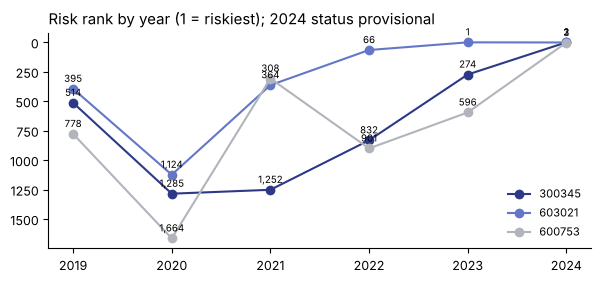

In [27]:
codes_2024 = pbi[pbi.feature_year == 2024].sort_values("risk_rank").stock_code
FIRMS = list(codes_2024.iloc[:3]) + ["900957"]          # the 2024 top 3 on this file, plus the firm with no 2025 status yet

def firm_detail(code):
    f = pbi[pbi.stock_code == code].sort_values("feature_year")
    rows = [r for r in pbi.itertuples() if r.stock_code == code]
    piv = pbi.pivot_table(index="stock_code", columns="feature_year", values="risk_rank", aggfunc="first").loc[code].dropna()
    r24 = f[f.feature_year == 2024]
    tiles = {
        "2024 rank": (int(r24.risk_rank.iloc[0]), int(piv[2024]), next(r.risk_rank for r in rows if r.feature_year == 2024)),
        "of N firms": (int(r24.firms_scored_in_year.iloc[0]), int(pbi[pbi.feature_year == 2024].stock_code.nunique()), sum(1 for r in pbi.itertuples() if r.feature_year == 2024)),
        "years in High": (int((f.risk_band == "High").sum()), int(pbi[pbi.stock_code == code].groupby("risk_band").size().get("High", 0)), sum(1 for r in rows if r.risk_band == "High")),
        "years scored": (len(f), len(piv), len(rows)),
        "highest-ranked year": (int(f.sort_values(["risk_rank", "feature_year"]).feature_year.iloc[0]), int(piv.idxmin()), min(rows, key=lambda r: (r.risk_rank, r.feature_year)).feature_year),
    }
    return f, tiles

for code in FIRMS:
    f, tiles = firm_detail(code)
    if len(f) == 0:
        print(f"\n{code}: not in this file, skipped"); continue
    print(f"\nStock code = {code}")
    for name, (a, b, c) in tiles.items():
        check("dash", f"Firm detail {code}: {name}", a, {"pandas filter": a, "pivot_table": b, "loop": c})
    band24 = f.loc[f.feature_year == 2024, "risk_band"].iloc[0]
    status = f.loc[f.feature_year == 2024, "st_status"].iloc[0]
    print(f"Power BI should show: 2024 risk rank {tiles['2024 rank'][0]:,} of {tiles['of N firms'][0]:,} | band {band24} | "
          f"{tiles['years in High'][0]} of {tiles['years scored'][0]} years in High | highest-ranked year {tiles['highest-ranked year'][0]} "
          f"| 2025 status {status.lower()}")
    detail = f[["feature_year", "risk_rank", "risk_band", "reason_1", "reason_2", "reason_3"]].rename(
        columns={"feature_year": "Year", "risk_rank": "Rank", "risk_band": "Band", "reason_1": "Reason 1", "reason_2": "Reason 2", "reason_3": "Reason 3"})
    display(detail.fillna("").reset_index(drop=True))

# The rank-by-year line for the 2024 top 3 (1 = riskiest, so the axis is upside down, as in Power BI)
fig, ax = plt.subplots(figsize=(7, 2.8))
for code, colour in zip(FIRMS[:3], [NAVY, "#6477C7", GREY]):
    f = pbi[pbi.stock_code == code].sort_values("feature_year")
    ax.plot(f.feature_year, f.risk_rank, marker="o", color=colour, label=code)
    for x, y in zip(f.feature_year, f.risk_rank):
        ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=7)
ax.invert_yaxis(); ax.legend(frameon=False, fontsize=8); ax.set_title("Risk rank by year (1 = riskiest); 2024 status provisional", loc="left"); plt.show()

### I.4 Model check page: the 2023-2024 check chart

The rule, per feature year: **caught** = ST cases among High-band firms, **ST cases** = all ST cases. The page slicers (Year, Region, Listing board, Industry) filter this chart only. 2024 uses the provisional 2025 status; the one firm with no 2025 status counts as blank, not as 0 or 1.


Combination A: everything All
PASS  | dashboard | Check chart A, 2023: High band caught: expected 53 | pandas filter: 53 | pivot_table: 53 | loop: 53
PASS  | dashboard | Check chart A, 2023: ST cases: expected 92 | pandas filter: 92 | pivot_table: 92 | loop: 92
PASS  | dashboard | Check chart A, 2024 (provisional): High band caught: expected 75 | pandas filter: 75 | pivot_table: 75 | loop: 75
PASS  | dashboard | Check chart A, 2024 (provisional): ST cases: expected 115 | pandas filter: 115 | pivot_table: 115 | loop: 115
Power BI should show: 2023: 53 of 92 (57.6%) | 2024: 75 of 115 (65.2%) (provisional)

Combination B: Region = East
PASS  | dashboard | Check chart B, 2023: High band caught: expected 36 | pandas filter: 36 | pivot_table: 36 | loop: 36
PASS  | dashboard | Check chart B, 2023: ST cases: expected 63 | pandas filter: 63 | pivot_table: 63 | loop: 63
PASS  | dashboard | Check chart B, 2024 (provisional): High band caught: expected 50 | pandas filter: 50 | pivot_table: 50 | l

PASS  | dashboard | Check chart D, 2023: High band caught: expected 15 | pandas filter: 15 | pivot_table: 15 | loop: 15
PASS  | dashboard | Check chart D, 2023: ST cases: expected 26 | pandas filter: 26 | pivot_table: 26 | loop: 26
PASS  | dashboard | Check chart D, 2024 (provisional): High band caught: expected 26 | pandas filter: 26 | pivot_table: 26 | loop: 26
PASS  | dashboard | Check chart D, 2024 (provisional): ST cases: expected 40 | pandas filter: 40 | pivot_table: 40 | loop: 40
Power BI should show: 2023: 15 of 26 (57.7%) | 2024: 26 of 40 (65.0%) (provisional)

Combination E: Region = West, Listing board = Main board
PASS  | dashboard | Check chart E, 2023: High band caught: expected 8 | pandas filter: 8 | pivot_table: 8 | loop: 8
PASS  | dashboard | Check chart E, 2023: ST cases: expected 12 | pandas filter: 12 | pivot_table: 12 | loop: 12
PASS  | dashboard | Check chart E, 2024 (provisional): High band caught: expected 10 | pandas filter: 10 | pivot_table: 10 | loop: 10
PASS

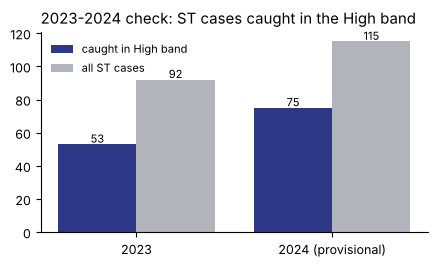

In [28]:
chk = pbi[pbi.period == "check"]
CHECK_COMBOS = [("A", {}), ("B", {"region": "East"}), ("C", {"board": ["Main board", "ChiNext"]}), ("D", {"industry": "C3"}), ("E", {"region": "West", "board": "Main board"})]
for name, sl in CHECK_COMBOS:
    print(f"\nCombination {name}: {describe(sl)}")
    f = apply_slicers(chk, **sl)
    keys = [SLICER_COLS[k] for k in sl]
    piv = chk.pivot_table(index=keys + ["feature_year", "risk_band"], values="st_next_year", aggfunc="sum").reset_index()
    for k, v in sl.items():
        c = SLICER_COLS[k]; piv = piv[piv[c].isin(v)] if isinstance(v, (list, tuple, set)) else piv[piv[c] == v]
    rows = loop_rows(chk, **sl)
    line = []
    for yr in (2023, 2024):
        caught = (f.loc[(f.feature_year == yr) & (f.risk_band == "High"), "st_next_year"].sum(),
                  piv.loc[(piv.feature_year == yr) & (piv.risk_band == "High"), "st_next_year"].sum(),
                  sum(r.st_next_year for r in rows if r.feature_year == yr and r.risk_band == "High" and not pd.isna(r.st_next_year)))
        cases = (f.loc[f.feature_year == yr, "st_next_year"].sum(), piv.loc[piv.feature_year == yr, "st_next_year"].sum(),
                 sum(r.st_next_year for r in rows if r.feature_year == yr and not pd.isna(r.st_next_year)))
        deck_c, deck_n = {("A", 2023): (53, 92), ("A", 2024): (75, 115)}.get((name, yr), (caught[0], cases[0]))
        tag = " (provisional)" if yr == 2024 else ""
        check("dash", f"Check chart {name}, {yr}{tag}: High band caught", deck_c, {"pandas filter": caught[0], "pivot_table": caught[1], "loop": caught[2]})
        check("dash", f"Check chart {name}, {yr}{tag}: ST cases", deck_n, {"pandas filter": cases[0], "pivot_table": cases[1], "loop": cases[2]})
        line.append(f"{yr}: {int(caught[0])} of {int(cases[0])}" + (f" ({100 * caught[0] / cases[0]:.1f}%)" if cases[0] else "") + tag)
    print("Power BI should show: " + " | ".join(line))

# The chart for combination A, drawn the way the dashboard draws it
f = chk.groupby("feature_year").apply(lambda d: pd.Series({"caught in High band": d.loc[d.risk_band == "High", "st_next_year"].sum(), "all ST cases": d.st_next_year.sum()}))
fig, ax = plt.subplots(figsize=(5, 2.6))
x = np.arange(len(f))
ax.bar(x - 0.2, f["caught in High band"], 0.4, color=NAVY, label="caught in High band")
ax.bar(x + 0.2, f["all ST cases"], 0.4, color=GREY, label="all ST cases")
for i, (a, b) in enumerate(zip(f["caught in High band"], f["all ST cases"])):
    ax.text(i - 0.2, a + 1, f"{int(a)}", ha="center", fontsize=8); ax.text(i + 0.2, b + 1, f"{int(b)}", ha="center", fontsize=8)
ax.set_xticks(x, ["2023", "2024 (provisional)"]); ax.legend(frameon=False, fontsize=8)
ax.set_title("2023-2024 check: ST cases caught in the High band", loc="left"); plt.show()

## J. Summary

In [29]:
res = pd.DataFrame(RESULTS)
out = Path.cwd() / "verify_deck_checks.csv"
res.to_csv(out, index=False)
print(res.result.value_counts().to_string())
print(f"\n{len(res)} numbers checked, each three ways. Saved: {out}")
if (res.result == "CHECK").any():
    print("\nLook at these lines:")
    print(res.loc[res.result == "CHECK", ["slide", "check", "slide value", "way 1"]].to_string(index=False))
if (res.result == "BUILD").any():
    print("\nModel numbers that differ slightly from the slide (expected on another xgboost build; the deck keeps the original numbers):")
    print(res.loc[res.result == "BUILD", ["slide", "check", "slide value", "way 1"]].to_string(index=False))

result
PASS     164
BUILD      7

171 numbers checked, each three ways. Saved: <this folder>/verify_deck_checks.csv

Model numbers that differ slightly from the slide (expected on another xgboost build; the deck keeps the original numbers):
slide                                         check  slide value               way 1
   21         PR-AUC as a multiple of the base rate         16.2 scikit-learn = 17.0
   26                         Medium band: ST cases         26.0       group-by = 28
   26                            Low band: ST cases         18.0       group-by = 16
   22         XGBoost, 2023-2024: Recall@Top10% (%)         61.4 rank in year = 61.8
   24 profitability and losses: share of |SHAP| (%)         65.0   family sum = 63.5
 dash     band chart from the file: Medium ST cases         26.0        groupby = 28
 dash        band chart from the file: Low ST cases         18.0        groupby = 16
